# Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import json
import math
import heapq
from scipy.stats import pearsonr
from copy import deepcopy

# Exploration

## Data CSV

In [ ]:
data_df = pd.read_csv('TMDB 5000/tmdb_5000_movies.csv', index_col=False)

Cleaning the JSON columns

We make each of the JSON column into a seperate table and create a new table to link the parent and the child tables

### Genre cleaning

In [ ]:
genres = [eval(i) for i in data_df['genres']]

In [ ]:
unique_genres = dict()

for i in genres:
    for j in i:
        unique_genres[str(j['id'])] = j['name']

In [ ]:
total_genres = [{'id':i, 'name': unique_genres[i]} for i in unique_genres]

In [ ]:
with open('genres.json', 'w') as f:
    json.dump(total_genres, f)
genres_df = pd.read_json('genres.json')
genres_df.to_csv('genres.csv', index=False)

In [ ]:
genre_mapping = []
genre_data = data_df[['genres', 'id']]
for i in range(len(genre_data)):
    movie_row = genre_data.iloc[i]
    for j in eval(movie_row['genres']):
        genre_mapping.append({
            "movie_id": int(genre_data.iloc[i]['id']),
            "genre_id": j['id']
        })

In [ ]:
with open('genre_mapping.json', 'w') as f:
    json.dump(genre_mapping, f)
genres_map_df = pd.read_json('genre_mapping.json')
genres_map_df.to_csv('genre_mapping.csv', index=False)

In [ ]:
# data_df['genres'] = genres_df['id']

### Keywords Cleaning

In [ ]:
keywords = [eval(i) for i in data_df['keywords']]
unique_keywords = dict()

# creating keywords table
for i in keywords:
    for j in i:
        unique_keywords[str(j['id'])] = j['name']
total_keywords = [{'id':i, 'name': unique_keywords[i]} for i in unique_keywords]
with open('keywords.json', 'w') as f:
    json.dump(total_keywords, f)
keywords_df = pd.read_json('keywords.json')
keywords_df.to_csv('keywords.csv', index=False)

# creating keywords mapping table
keywords_mapping = []
keywords_data = data_df[['keywords', 'id']]
for i in range(len(keywords_data)):
    movie_row = keywords_data.iloc[i]
    for j in eval(movie_row['keywords']):
        keywords_mapping.append({
            "movie_id": int(keywords_data.iloc[i]['id']),
            "keyword_id": j['id']
        })
with open('keywords_mapping.json', 'w') as f:
    json.dump(keywords_mapping, f)
keywords_map_df = pd.read_json('keywords_mapping.json')
keywords_map_df.to_csv('keywords_mapping.csv', index=False)

In [ ]:
# data_df['keywords'] = keywords_df['id']

### Production Companies cleaning

In [ ]:
companies = [eval(i) for i in data_df['production_companies']]
unique_companies = dict()

for i in companies:
    for j in i:
        unique_companies[str(j['id'])] = j['name']
total_companies = [{'id':i, 'name': unique_companies[i]} for i in unique_companies]
with open('companies.json', 'w') as f:
    json.dump(total_companies, f)
companies_df = pd.read_json('companies.json')
companies_df.to_csv('companies.csv', index=False)
companies_mapping = []
companies_data = data_df[['production_companies', 'id']]
for i in range(len(companies_data)):
    movie_row = companies_data.iloc[i]
    for j in eval(movie_row['production_companies']):
        companies_mapping.append({
            "movie_id": int(companies_data.iloc[i]['id']),
            "companies_id": j['id']
        })
with open('companies_mapping.json', 'w') as f:
    json.dump(companies_mapping, f)
companies_map_df = pd.read_json('companies_mapping.json')
companies_map_df.to_csv('companies_mapping.csv', index=False)

In [ ]:
# data_df['production_companies'] = companies_df['id']

### Production Countries cleaning

In [ ]:
companies = [eval(i) for i in data_df['production_countries']]

In [ ]:
companies[0]

[{'iso_3166_1': 'US', 'name': 'United States of America'},
 {'iso_3166_1': 'GB', 'name': 'United Kingdom'}]

In [ ]:
companies = [eval(i) for i in data_df['production_countries']]
unique_companies = dict()

for i in companies:
    for j in i:
        unique_companies[str(j['iso_3166_1'])] = j['name']
total_companies = [{'iso_3166_1':i, 'name': unique_companies[i]} for i in unique_companies]
with open('countries.json', 'w') as f:
    json.dump(total_companies, f)
companies_df = pd.read_json('countries.json')
companies_df.to_csv('countries.csv', index=False)
companies_mapping = []
companies_data = data_df[['production_countries', 'id']]
for i in range(len(companies_data)):
    movie_row = companies_data.iloc[i]
    for j in eval(movie_row['production_countries']):
        companies_mapping.append({
            "movie_id": int(companies_data.iloc[i]['id']),
            "countries_id": j['iso_3166_1']
        })
with open('countries_mapping.json', 'w') as f:
    json.dump(companies_mapping, f)
companies_map_df = pd.read_json('countries_mapping.json')
companies_map_df.to_csv('countries_mapping.csv', index=False)

In [ ]:
# data_df['production_countries'] = countries_df['iso_3166_1']

### Spoken Langauges cleaning

In [ ]:
companies = [eval(i) for i in data_df['spoken_languages']]
unique_companies = dict()

for i in companies:
    for j in i:
        unique_companies[str(j['iso_639_1'])] = j['name']
total_companies = [{'iso_639_1':i, 'name': unique_companies[i]} for i in unique_companies]
with open('languages.json', 'w') as f:
    json.dump(total_companies, f)
companies_df = pd.read_json('languages.json')
companies_df.to_csv('languages.csv', index=False)
companies_mapping = []
companies_data = data_df[['spoken_languages', 'id']]
for i in range(len(companies_data)):
    movie_row = companies_data.iloc[i]
    for j in eval(movie_row['spoken_languages']):
        companies_mapping.append({
            "movie_id": int(companies_data.iloc[i]['id']),
            "languages_id": j['iso_639_1']
        })
with open('languages_mapping.json', 'w') as f:
    json.dump(companies_mapping, f)
companies_map_df = pd.read_json('languages_mapping.json')
companies_map_df.to_csv('languages_mapping.csv', index=False)

In [ ]:
# data_df['spoken_languages'] = lang_df['iso_639_1']

### Total

In [ ]:
# dropping these columns as either no use or redudant
data_df = data_df.drop([
    'homepage', 'genres', 'keywords', 'production_companies', 'production_countries',
    'spoken_languages'], axis='columns')

In [ ]:
data_df.to_csv('TMDB 5000 Cleaned.csv', index=False)

## Credits CSV

In [ ]:
credits_df = pd.read_csv('TMDB 5000/tmdb_5000_credits.csv', index_col=False)

### Cast

In [ ]:
cast = [eval(i) for i in credits_df['cast']]
unique_cast = dict()

# creating cast table
for i in cast:
    for j in i:
        k = deepcopy(j)
        del k['cast_id']
        unique_cast[str(j['cast_id'])] = k
total_cast = [{'cast_id':i, 'cast': unique_cast[i]} for i in unique_cast]
with open('cast.json', 'w') as f:
    json.dump(total_cast, f)
cast_df = pd.read_json('cast.json')
cast_df.to_csv('cast.csv', index=False)
cast_data = credits_df[['cast', 'movie_id']]

# creating cast mapping table
cast_mapping = []
for i in range(len(cast_data)):
    movie_row = cast_data.iloc[i]
    for j in eval(movie_row['cast']):
        cast_mapping.append({
            "movie_id": int(movie_row['movie_id']),
            "cast_id": j['cast_id']
        })
with open('cast_mapping.json', 'w') as f:
    json.dump(cast_mapping, f)
cast_map_df = pd.read_json('cast_mapping.json')
cast_map_df.to_csv('cast_mapping.csv', index=False)

### Crew

In [ ]:
cast = [eval(i) for i in credits_df['crew']]

In [ ]:
cast = [eval(i) for i in credits_df['crew']]
unique_companies = dict()

for i in cast:
    for j in i:
        k = deepcopy(j)
        del k['credit_id']
        unique_companies[str(j['credit_id'])] = k
total_companies = [{'credit_id':i, 'crew': unique_companies[i]} for i in unique_companies]
with open('crew.json', 'w') as f:
    json.dump(total_companies, f)
companies_df = pd.read_json('crew.json')
companies_df.to_csv('crew.csv', index=False)
companies_data = credits_df[['crew', 'movie_id']]
companies_mapping = []
for i in range(len(companies_data)):
    movie_row = companies_data.iloc[i]
    for j in eval(movie_row['crew']):
        companies_mapping.append({
            "movie_id": int(movie_row['movie_id']),
            "credit_id": j['credit_id']
        })
with open('crew_mapping.json', 'w') as f:
    json.dump(companies_mapping, f)
companies_map_df = pd.read_json('crew_mapping.json')
companies_map_df.to_csv('crew_mapping.csv', index=False)

# Database Schema

![Movies Database schema](./schema.png)

# Hypothesis: Runtime has increase over the decades

# Preparing for visualization

In [2]:
movies_df = pd.read_csv('data/TMDB_5000_Cleaned.csv')
cast_df = pd.read_csv('data/cast.csv')
crew_df = pd.read_csv('data/crew.csv')
companies_df = pd.read_csv('data/companies.csv')
countries_df = pd.read_csv('data/countries.csv')
genres_df = pd.read_csv('data/genres.csv')
languages_df = pd.read_csv('data/languages.csv')
cast_map_df = pd.read_csv('data/cast_mapping.csv')
crew_map_df = pd.read_csv('data/crew_mapping.csv')
companies_map_df = pd.read_csv('data/companies_mapping.csv')
countries_map_df = pd.read_csv('data/countries_mapping.csv')
genres_map_df = pd.read_csv('data/genre_mapping.csv')
languages_map_df = pd.read_csv('data/languages_mapping.csv')

In [3]:
movies_df = movies_df.dropna()

In [4]:
movies_df['profit'] = movies_df['revenue'] - movies_df['budget']

In [5]:
movies_df.keys()

Index(['budget', 'id', 'original_language', 'original_title', 'overview',
       'popularity', 'release_date', 'revenue', 'runtime', 'status', 'tagline',
       'title', 'vote_average', 'vote_count', 'profit'],
      dtype='object')

In [6]:
release_years = [i.split('-')[0] for i in list(movies_df['release_date'])]

overview, release_date, runtime, tagline have NaN values<br>
cast_id = 41 character is NaN

# Box plot trend across the years

In [ ]:
for measure in ['runtime', 'revenue', 'budget', 'popularity']:
    x = list(set(list(movies_df['release_date'])))
    # get the total measure for a release_date
    y = [sum(movies_df[movies_df['release_date'] == i][measure]) for i in x]
    
    ordered_pop = {i:j for i, j in zip(x, y)}
    s = sorted(x)
    order_pop = {i: ordered_pop[i] for i in s}  # ordered wrt date
    years = sorted([eval(i.split('-')[0]) for i in order_pop])
    decades = range(1910, 2020, 10)  # display data according to years
    
    # get a representative for each decade
    gaps = [str(int(np.median([year for year in years if decade<=year<(decade+10)]))) for decade in decades]
    y_vals = order_pop.values()
    gap_y = dict()
    for i in order_pop:

        # get the corresponding prefix for a decade e.g 197 for 1970s
        m_year = [j for j in gaps if j.startswith((i.split('-')[0][:-1]))][0]
        if m_year not in gap_y:
            gap_y[m_year] = [order_pop[i]]
        else:
            gap_y[m_year].append(order_pop[i])
    # collect the max for each decade
    gap_y = {i: max(gap_y[i]) for i in gap_y}
    x_vals = gap_y.keys()
    y_vals = gap_y.values()
    sns.lineplot(x = x_vals, y = y_vals)
    plt.xlabel('The median year from each Decade')
    
    title = ""
    if measure == 'runtime':
        title = f'Maximum {measure.capitalize()} in minutes'
    elif measure == 'popularity':
        title = f' Maximum {measure.capitalize()}'
    else:
        title = f'Maximum {measure.capitalize()} in dollars'
    plt.ylabel(title)
    plt.title(f'Maximum {measure.capitalize()} over the decades')
    plt.savefig(f'data/max_{measure}_year.png')
    plt.show()

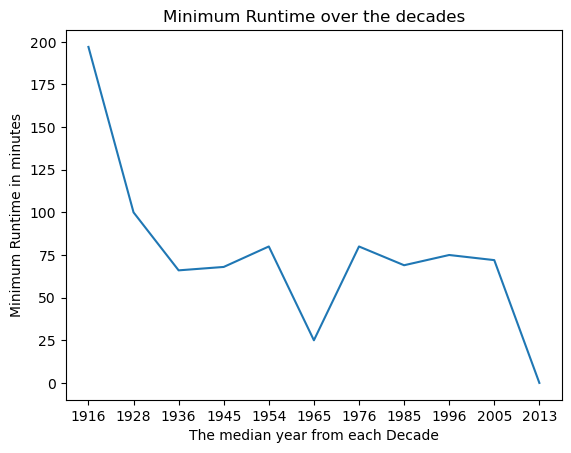

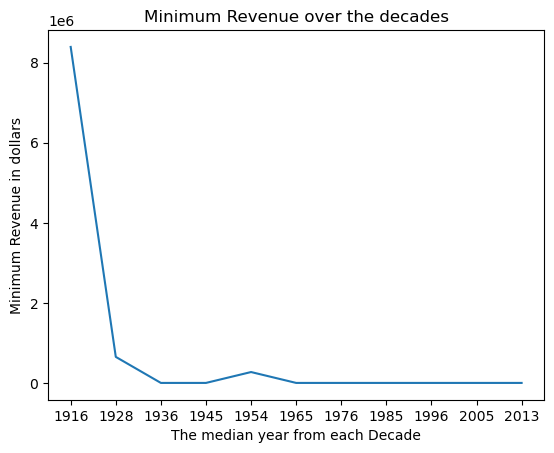

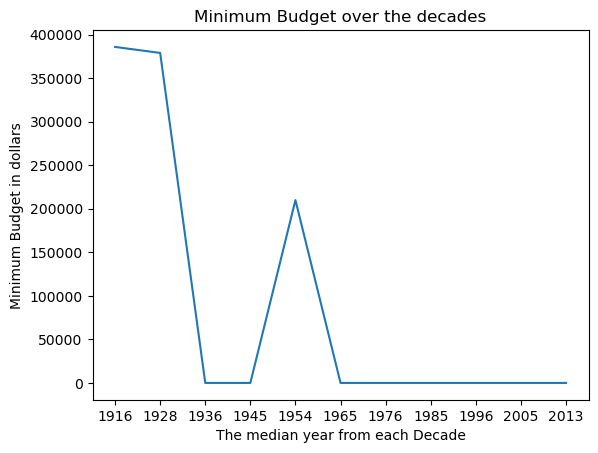

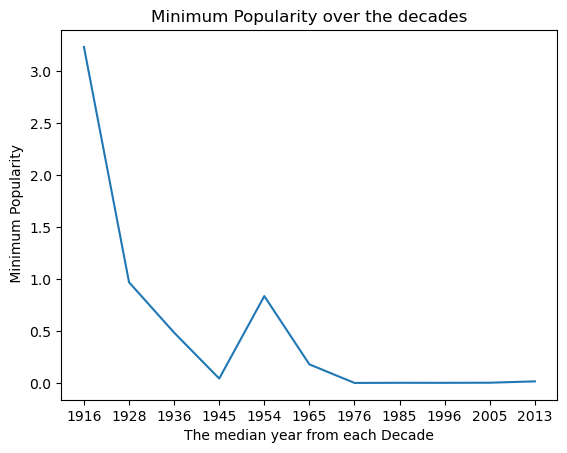

In [ ]:
for measure in ['runtime', 'revenue', 'budget', 'popularity']:
    x = list(set(list(movies_df['release_date'])))
    # get the total measure for a release_date
    y = [sum(movies_df[movies_df['release_date'] == i][measure]) for i in x]
    
    ordered_pop = {i:j for i, j in zip(x, y)}
    s = sorted(x)
    order_pop = {i: ordered_pop[i] for i in s}  # ordered wrt date
    years = sorted([eval(i.split('-')[0]) for i in order_pop])
    decades = range(1910, 2020, 10)  # display data according to years
    
    # get a representative for each decade
    gaps = [str(int(np.median([year for year in years if decade<=year<(decade+10)]))) for decade in decades]
    y_vals = order_pop.values()
    gap_y = dict()
    for i in order_pop:
        # get the corresponding prefix for a decade e.g 197 for 1970s
        m_year = [j for j in gaps if j.startswith((i.split('-')[0][:-1]))][0]
        if m_year not in gap_y:
            gap_y[m_year] = [order_pop[i]]
        else:
            gap_y[m_year].append(order_pop[i])
    # collect the min for each decade
    gap_y = {i: min(gap_y[i]) for i in gap_y}
    x_vals = gap_y.keys()
    y_vals = gap_y.values()
    sns.lineplot(x = x_vals, y = y_vals)
    plt.xlabel('The median year from each Decade')
    
    title = ""
    if measure == 'runtime':
        title = f'Minimum {measure.capitalize()} in minutes'
    elif measure == 'popularity':
        title = f' Minimum {measure.capitalize()}'
    else:
        title = f'Minimum {measure.capitalize()} in dollars'
    plt.ylabel(title)
    plt.title(f'Minimum {measure.capitalize()} over the decades')
    plt.savefig(f'data/min_{measure}_year.png')
    plt.show()

# Line plot for trends

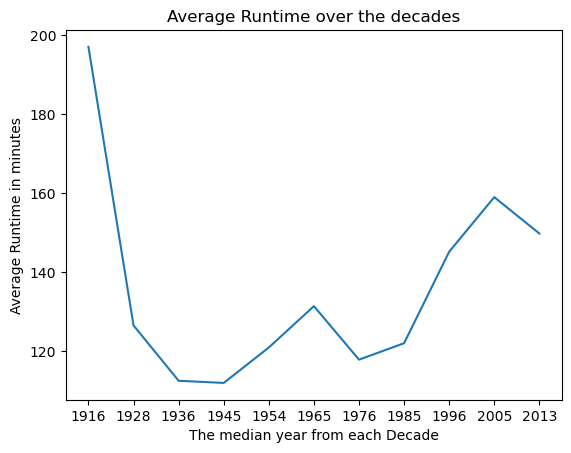

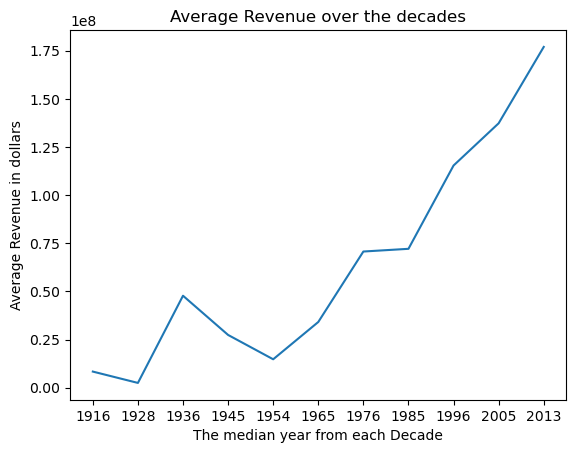

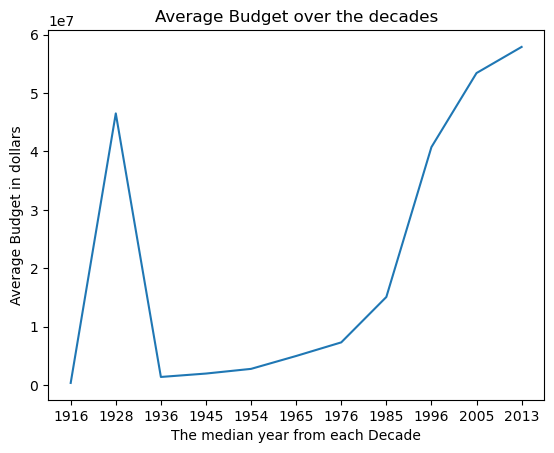

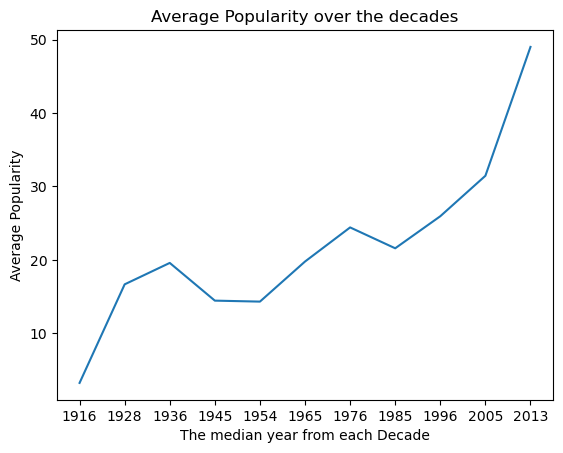

In [ ]:
for measure in ['runtime', 'revenue', 'budget', 'popularity']:
    x = list(set(list(movies_df['release_date'])))
    # get the total measure for a release_date
    y = [sum(movies_df[movies_df['release_date'] == i][measure]) for i in x]
    
    ordered_pop = {i:j for i, j in zip(x, y)}
    s = sorted(x)
    order_pop = {i: ordered_pop[i] for i in s}  # ordered wrt date
    years = sorted([eval(i.split('-')[0]) for i in order_pop])
    decades = range(1910, 2020, 10)  # display data according to years
    
    # get a representative for each decade
    gaps = [str(int(np.median([year for year in years if decade<=year<(decade+10)]))) for decade in decades]
    y_vals = order_pop.values()
    gap_y = dict()
    for i in order_pop:
        # get the corresponding prefix for a decade e.g 197 for 1970s
        m_year = [j for j in gaps if j.startswith((i.split('-')[0][:-1]))][0]
        if m_year not in gap_y:
            gap_y[m_year] = [order_pop[i]]
        else:
            gap_y[m_year].append(order_pop[i])
    # collect the average for each decade
    gap_y = {i: float(np.average(gap_y[i])) for i in gap_y}
    x_vals = gap_y.keys()
    y_vals = gap_y.values()
    sns.lineplot(x = x_vals, y = y_vals)
    plt.xlabel('The median year from each Decade')
    
    title = ""
    if measure == 'runtime':
        title = f'Average {measure.capitalize()} in minutes'
    elif measure == 'popularity':
        title = f'Average {measure.capitalize()}'
    else:
        title = f'Average {measure.capitalize()} in dollars'
    plt.ylabel(title)
    plt.title(f'Average {measure.capitalize()} over the decades')
    plt.savefig(f'data/avg_{measure}_year.png')
    plt.show()

# Pair plot

In [12]:
pair_df = movies_df[['budget', 'revenue', 'runtime','vote_average']]

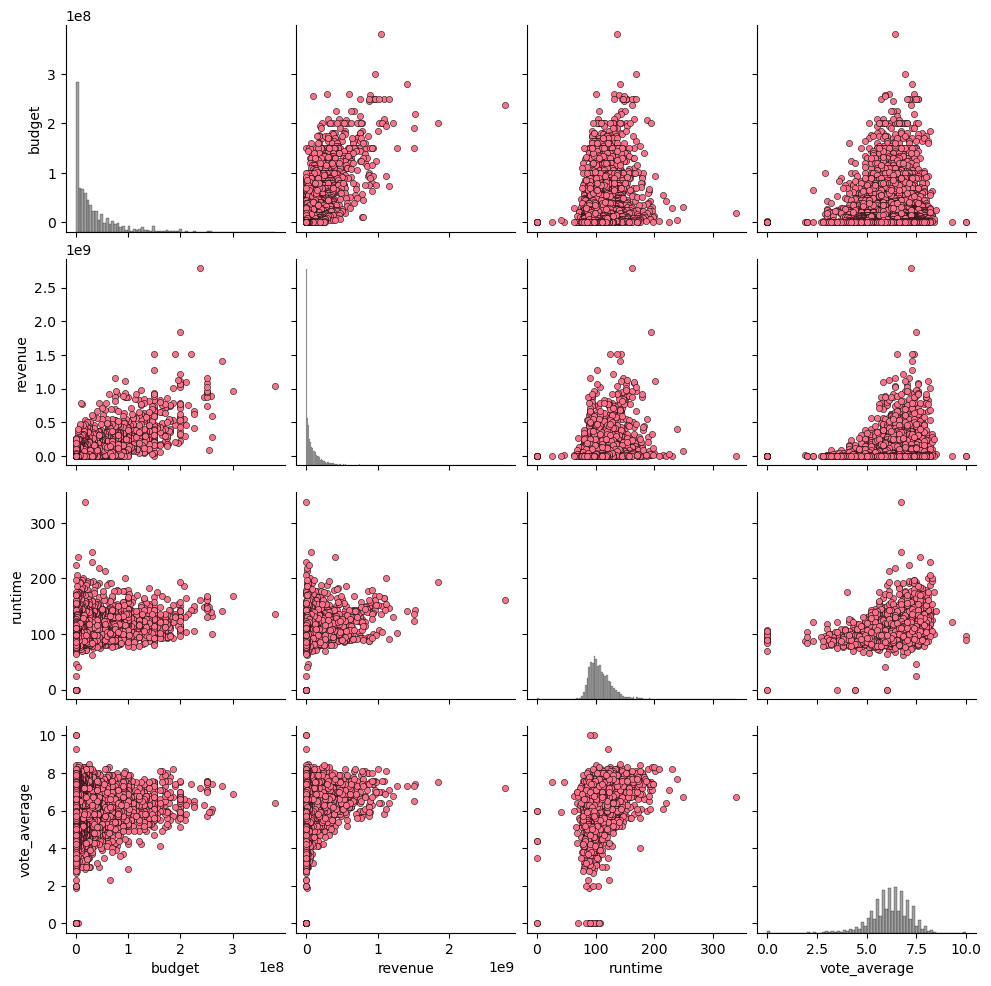

In [19]:
# sns.pairplot(pair_df)
sns.pairplot(
    data=pair_df,
    plot_kws={"alpha": 1, "s": 20, "edgecolor": "k"},  # semi-transparent points
    diag_kws={"fill": True, "color": "gray"},            # high-contrast histograms
)
plt.savefig('data/pair_plot.png')

# Correlation Matrix

In [ ]:
def create_correlation_heatmap(df, figsize=(12, 10), method='pearson',
        annot=True, cmap = "viridis", save_path='data/sample_correlation.png',
        title="Correlation Matrix"
    ):
    """
    Create a comprehensive correlation matrix heatmap
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The dataframe containing numerical variables
    figsize : tuple
        Figure size (width, height)
    method : str
        Correlation method ('pearson', 'kendall', 'spearman')
    annot : bool
        Whether to annotate cells with correlation values
    cmap : str
        Colormap for the heatmap
    save_path : str
        Path to save the figure (optional)
    title : str
        Title for the heatmap
    """
    
    # Select only numerical columns
    numeric_df = df.select_dtypes(include=[np.number])
    
    if numeric_df.empty:
        print("No numerical columns found in the dataframe!")
        return None
    
    # Calculate correlation matrix
    corr_matrix = numeric_df.corr(method=method)

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(corr_matrix, annot=annot,cmap=cmap, center=0, square=True, 
        linewidths=0.5,cbar_kws={"shrink": 0.8}, fmt='.2f', annot_kws={'size': 8}
    )
    
    plt.title(f'{title}\n({method.capitalize()} Correlation)', fontsize=16,
        fontweight='bold', pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Heatmap saved to: {save_path}")
    
    plt.show()
    
    return corr_matrix

def find_strong_correlations(corr_matrix, threshold=0.7):
    """
    Find and display strong correlations above the threshold
    """
    # Get upper triangle indices to avoid repeating
    upper_tri = np.triu(np.ones_like(corr_matrix), k=1).astype(bool)
    
    # Find strong correlations
    strong_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            corr_val = corr_matrix.iloc[i, j]
            if abs(corr_val) > threshold:  # compare with a threshold
                strong_corr.append({
                    'Variable 1': corr_matrix.columns[i],
                    'Variable 2': corr_matrix.columns[j],
                    'Correlation': corr_val
                })
    
    strong_corr_df = pd.DataFrame(strong_corr)
    strong_corr_df = strong_corr_df.sort_values('Correlation', key=abs, ascending=False)
    return strong_corr, strong_corr_df

# Additional customization options
def advanced_correlation_analysis(df):
    """
    Perform advanced correlation analysis with multiple methods
    """
    numeric_df = df.select_dtypes(include=[np.number])
    
    methods = ['pearson', 'spearman', 'kendall']
    all_corrs = []
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for i, method in enumerate(methods):
        corr = numeric_df.corr(method=method)
        all_corrs.append(corr)
        sns.heatmap(corr, annot=True,  cmap = "viridis", center=0, square=True, fmt='.2f',
                   ax=axes[i], cbar_kws={"shrink": 0.8})
        
        axes[i].set_title(f'{method.capitalize()} Correlation', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('data/complete_correlation.png')
    plt.show()
    return all_corrs

# For large datasets - select top correlated features
# def plot_top_correlations(df, target_column, top_n=10):
    # """
    # Plot correlations with a specific target variable
    # """
    # numeric_df = df.select_dtypes(include=[np.number])
    
    # if target_column not in numeric_df.columns:
    #     print(f"Target column '{target_column}' not found in numerical columns")
    #     return
    
    # # Calculate correlations with target
    # correlations = numeric_df.corr()[target_column].abs().sort_values(ascending=False)
    # top_corr = correlations.head(top_n + 1)[1:]  # Exclude self-correlation
    
    # plt.figure(figsize=(10, 6))
    # sns.barplot(x=top_corr.values, y=top_corr.index, palette='viridis')
    # plt.title(f'Top {top_n} Features Correlated with {target_column}')
    # plt.xlabel('Absolute Correlation')
    # plt.tight_layout()
    # plt.savefig('data/top_correlated_features.png')
    # plt.show()
    
    # return top_corr


1. Basic Correlation Heatmap:
Heatmap saved to: data/sample_correlation.png


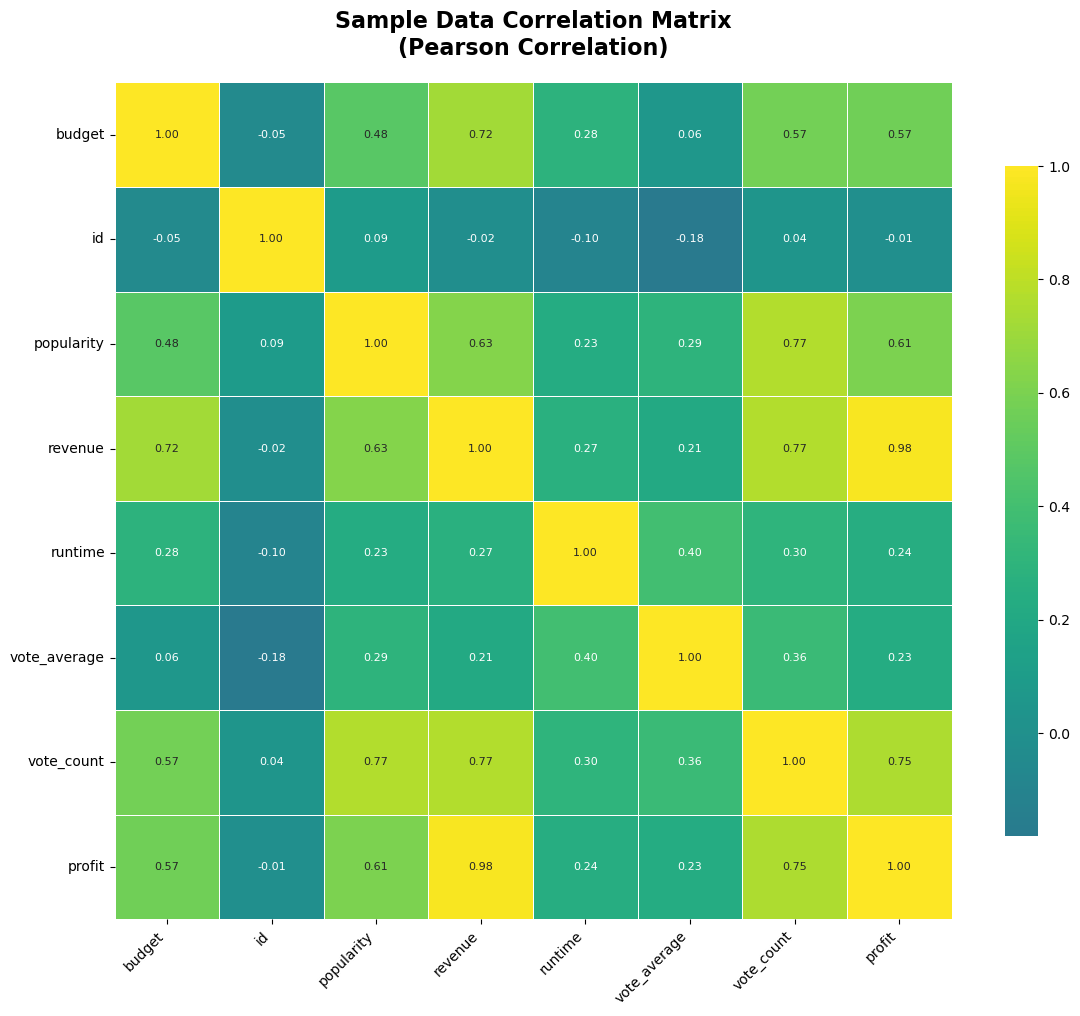


Strong correlations (|r| > 0.5):
--------------------------------------------------


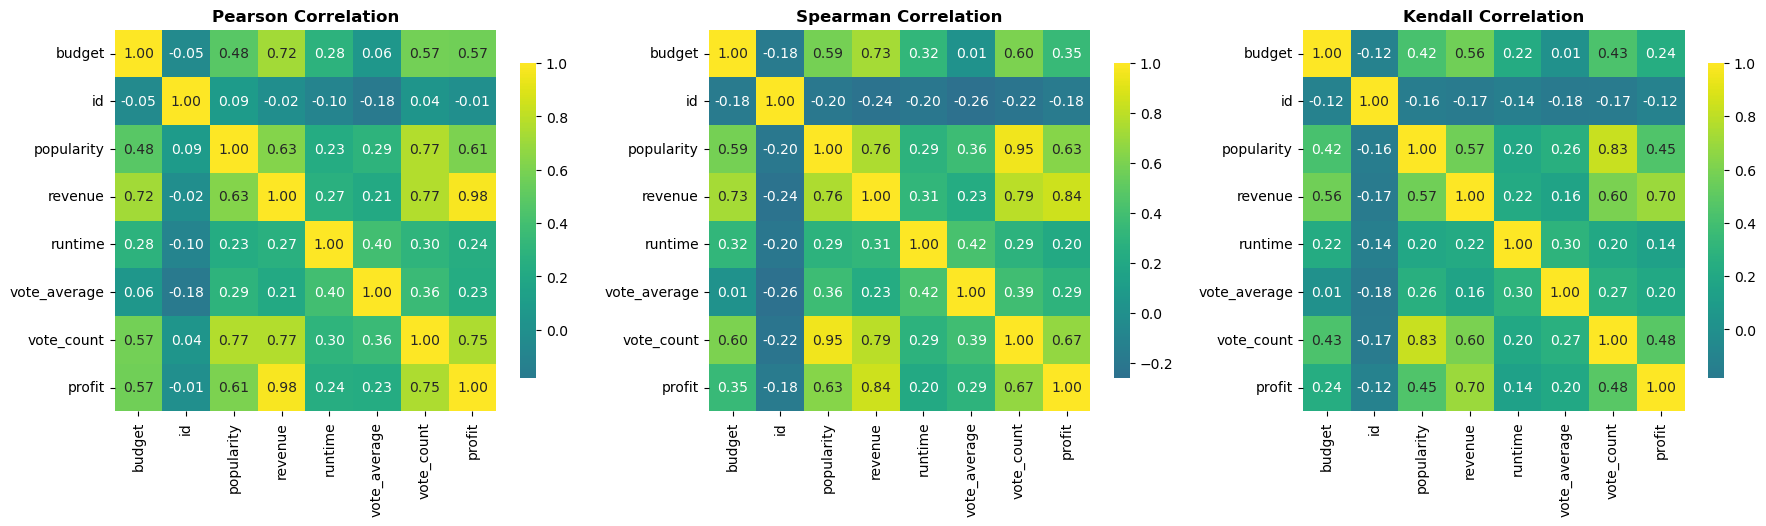

In [ ]:
plt.style.use('default')
sns.set_palette("husl")

print("\n1. Basic Correlation Heatmap:")
corr_matrix = create_correlation_heatmap(movies_df, title="Sample Data Correlation Matrix")
strong_corr, corr_df = find_strong_correlations(corr_matrix, threshold=0.5)
all_corrs = advanced_correlation_analysis(movies_df)

In [10]:
corr_df.to_csv('data/correlation.csv', index=False)

In [11]:
for i in range(len(all_corrs)):
    all_corrs[i].to_csv(f'data/correlation-{i}.csv', index=False)

# Ranked Genres

In [ ]:
genre_profit = dict()
for genre_id,name in zip(genres_df['id'], genres_df['name']):
    # Use genre_id to get movie_id from genres_map table
    movie_ids = genres_map_df[genres_map_df['genre_id'] == genre_id]['movie_id']
    
    c, b, r, t = [], [], [], []
    for movie_id in movie_ids:
        # movie rows for each movie_id
        movie_match = movies_df[movies_df['id'] == movie_id]
        profit, revenue, budget, runtime = (  # collect the attributes
                movie_match['profit'],
                movie_match['revenue'],
                movie_match['budget'],
                movie_match['runtime']
            )
        c.append(sum(profit))
        b.append(sum(budget))
        r.append(sum(revenue))
        t.append(sum(runtime))
    genre_profit[name] = {  # attributes per genre
        'profit':sum(c),
        'count': len(c),
        'revenue': float(np.average(r)),
        'budget': float(np.average(b)),
        'runtime': float(np.average(t))
        }

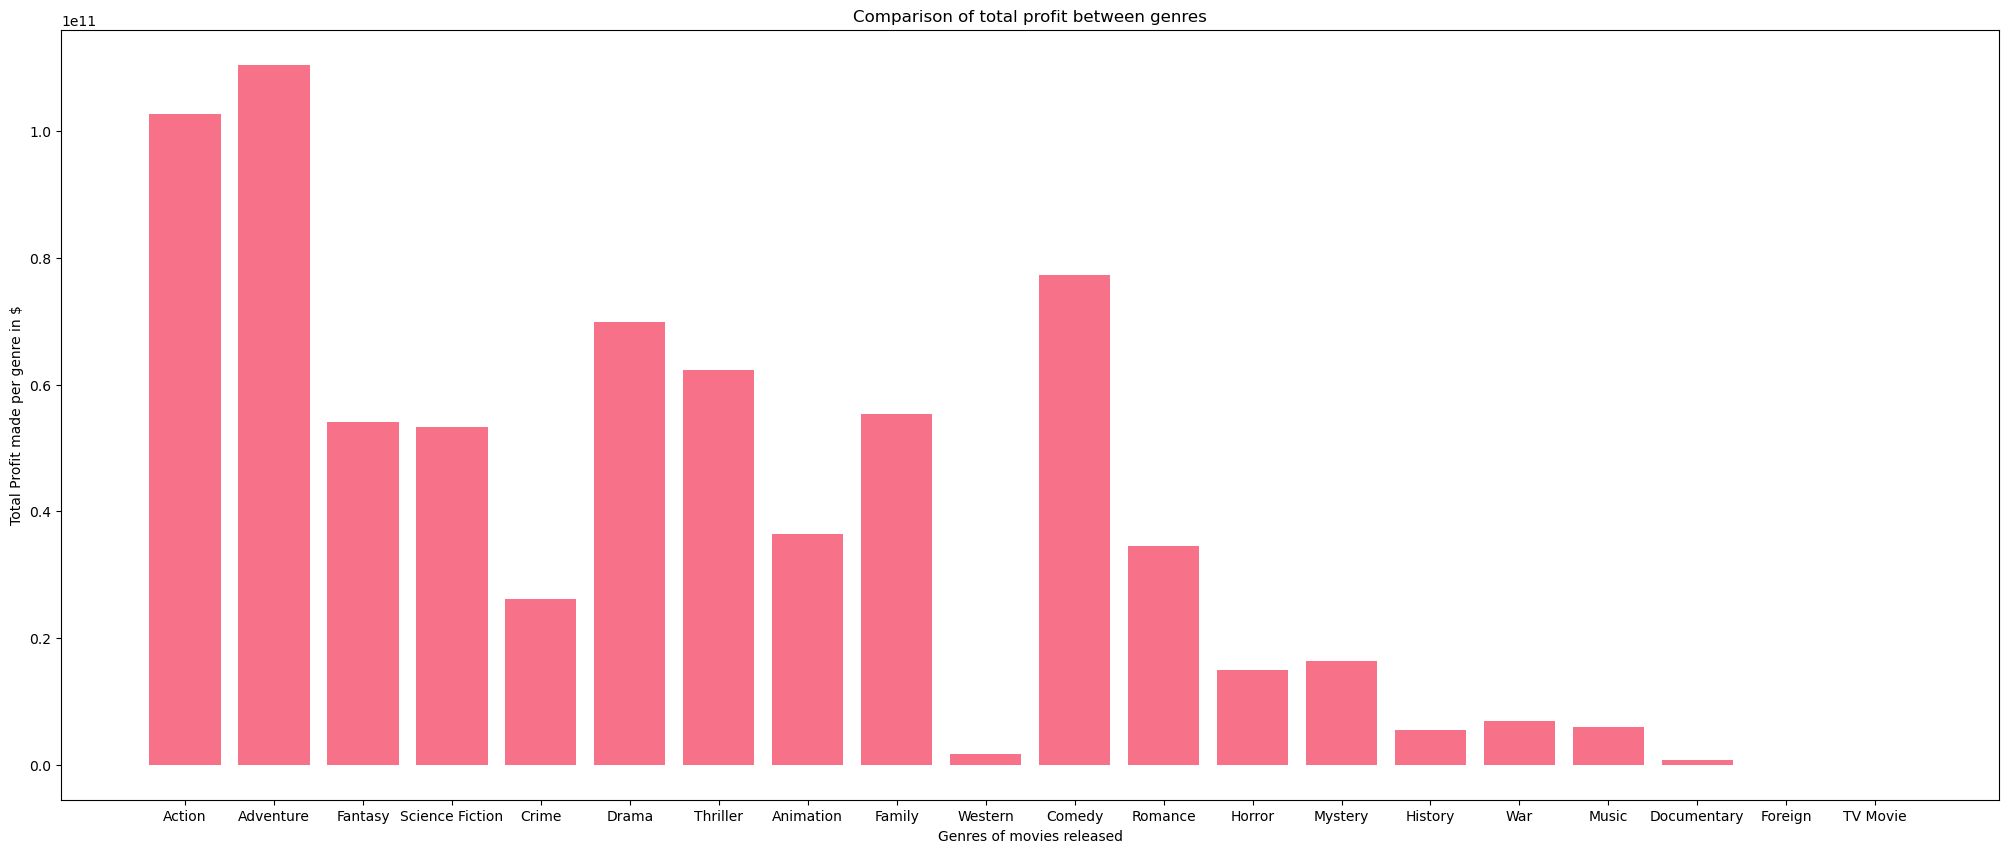

In [23]:
plt.figure(figsize=(25, 10))
x_vals = genre_profit.keys()
y1_vals = [genre_profit[genre]['profit'] for genre in genre_profit]

plt.bar(x_vals, y1_vals)
plt.xlabel('Genres of movies released')
plt.ylabel('Total Profit made per genre in $')
plt.title('Comparison of total profit between genres')
# plt.savefig('data/genres_profit.png')
plt.show()

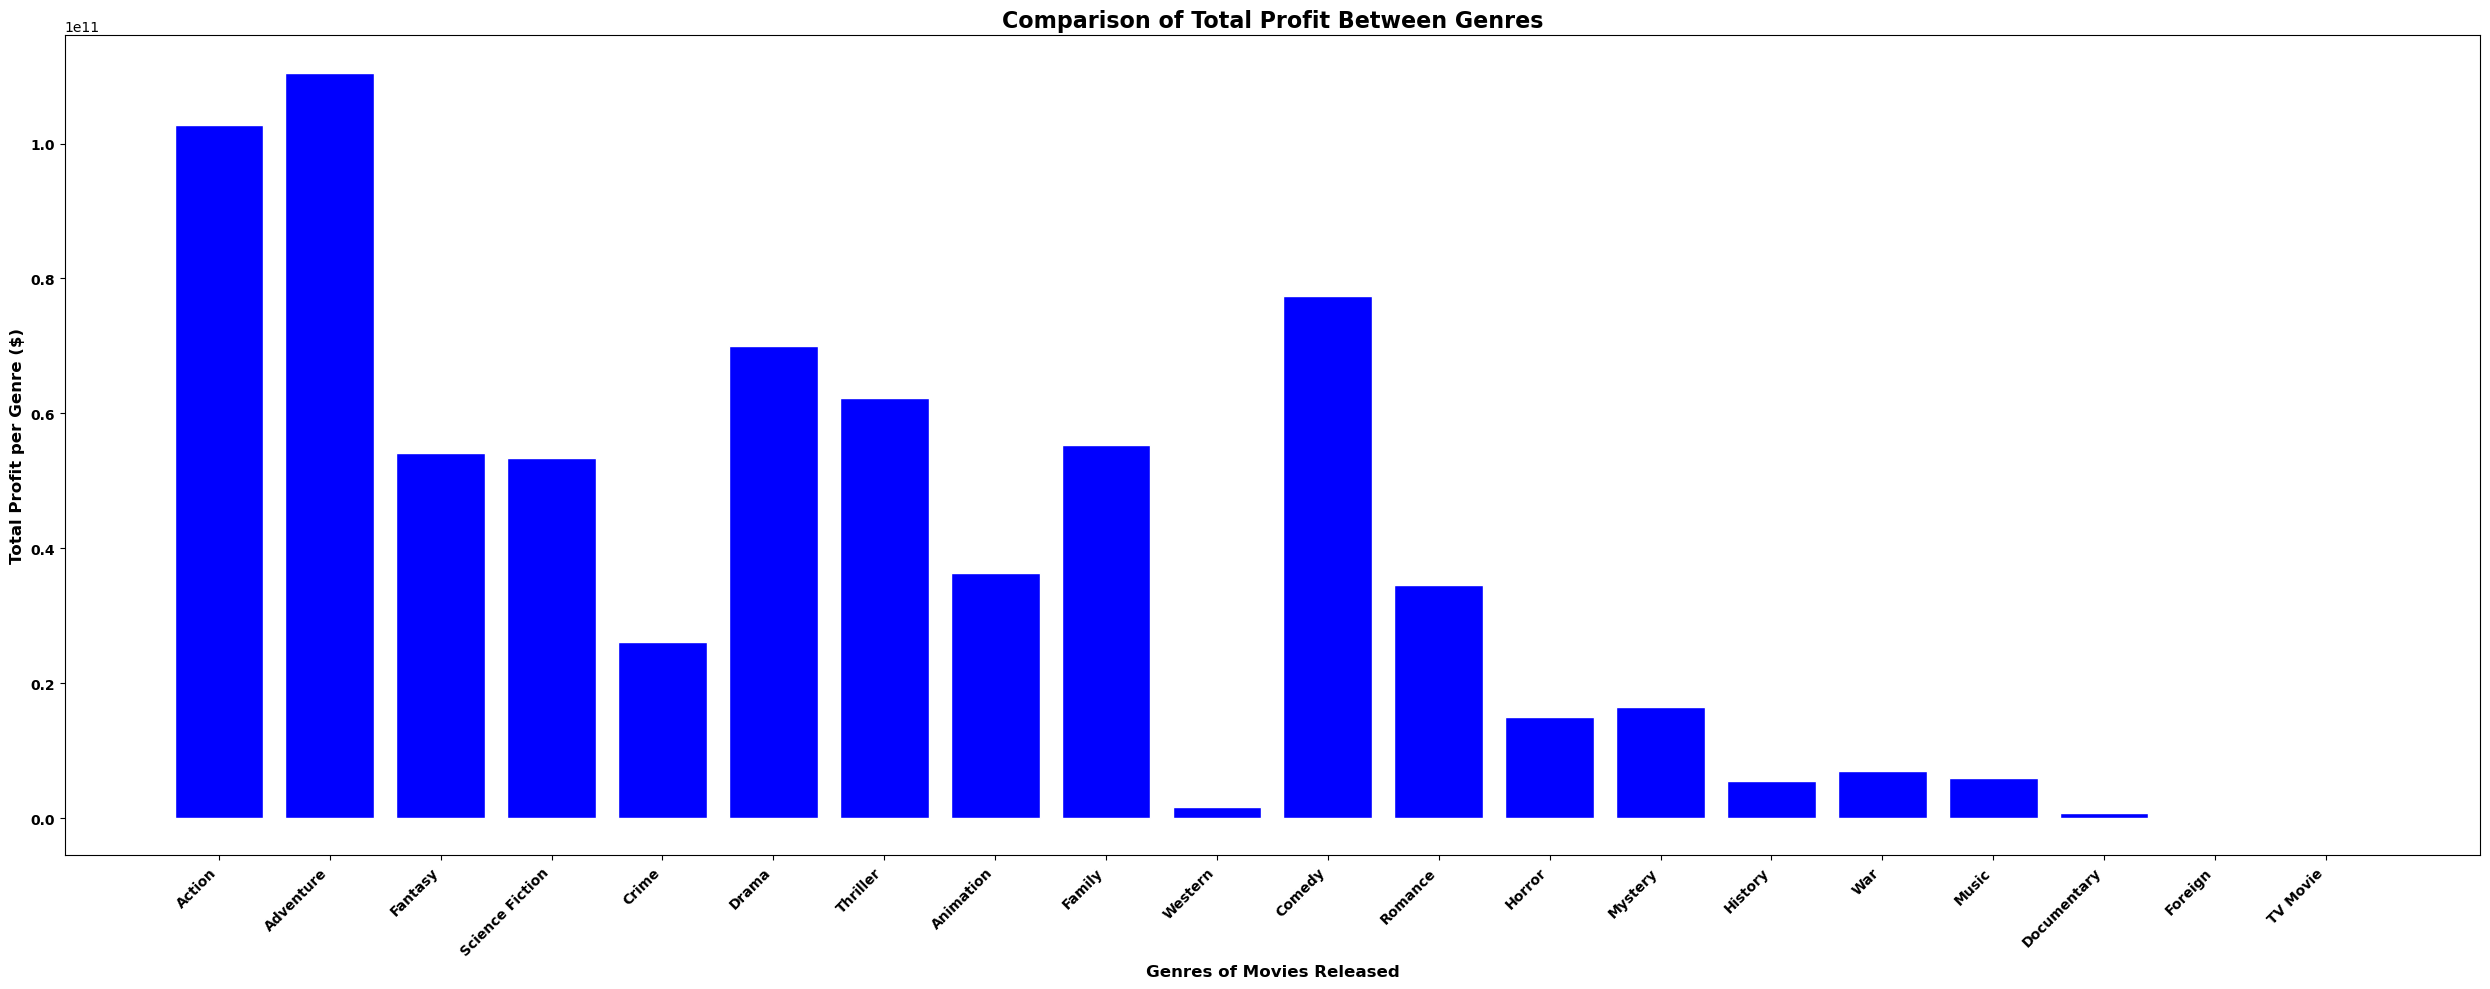

In [ ]:
fig, ax = plt.subplots(figsize=(25,10))
bars = ax.bar(
    x_vals, y1_vals,
    color="blue",        # solid high-contrast color
    edgecolor="white",    # outline for distinction
    linewidth=1
)
ax.set_xlabel("Genres of Movies Released", fontsize=12, fontweight="bold")
ax.set_ylabel("Total Profit per Genre ($)", fontsize=12, fontweight="bold")
ax.set_title("Comparison of Total Profit Between Genres", fontsize=16, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig("data/genres_profit_accessible.png", dpi=300, bbox_inches="tight")
plt.show()


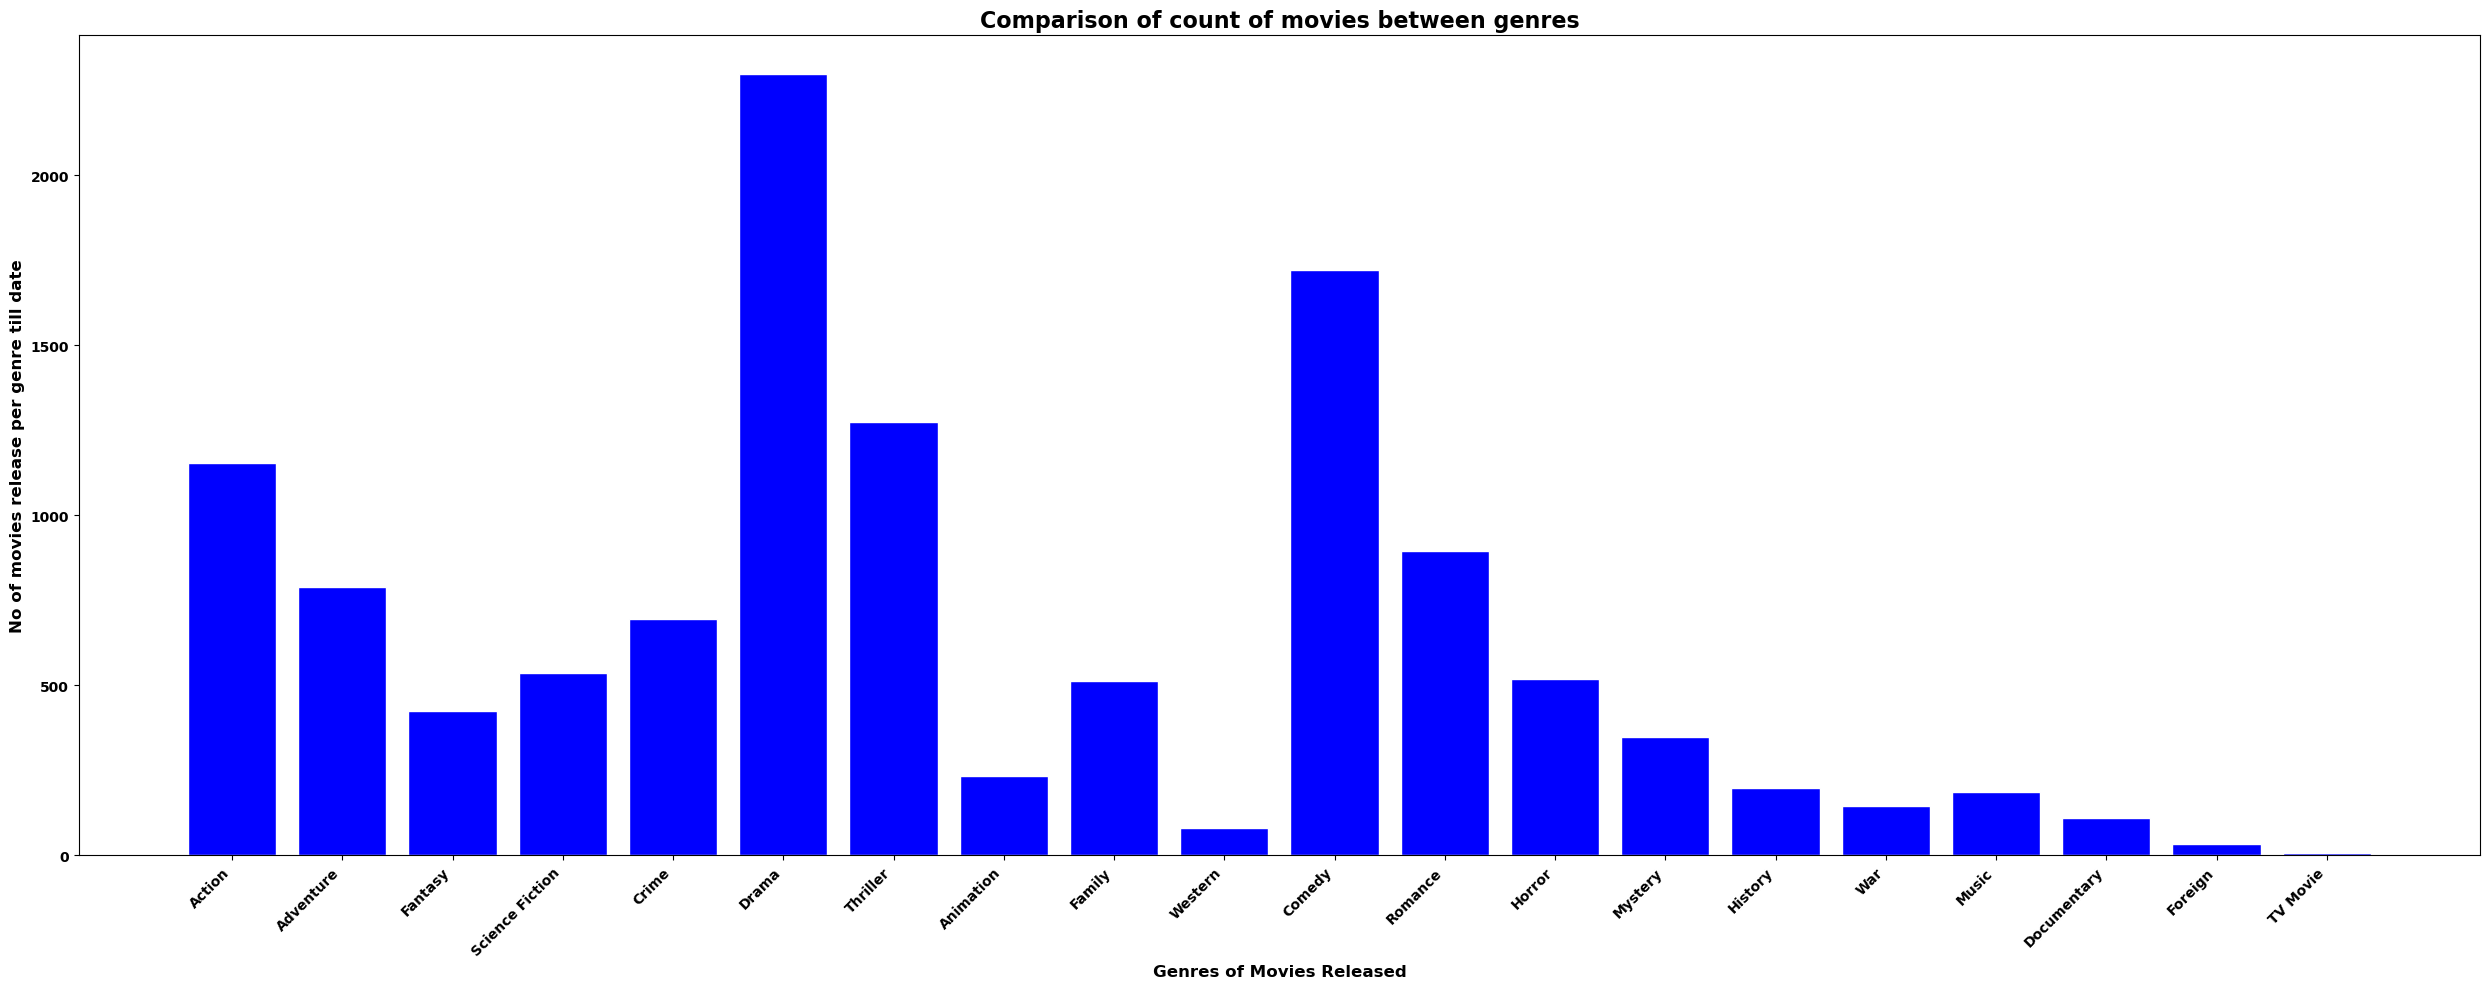

In [ ]:
fig, ax = plt.subplots(figsize=(25,10))
y2_vals = [genre_profit[genre]['count'] for genre in genre_profit]

bars = ax.bar(
    x_vals, y2_vals,
    color="blue",        # solid high-contrast color
    edgecolor="white",    # outline for distinction
    linewidth=1
)
ax.set_xlabel("Genres of Movies Released", fontsize=12, fontweight="bold")
ax.set_ylabel('No of movies release per genre till date', fontsize=12, fontweight="bold")
ax.set_title('Comparison of count of movies between genres', fontsize=16, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig('data/genres_count2.png')
plt.show()

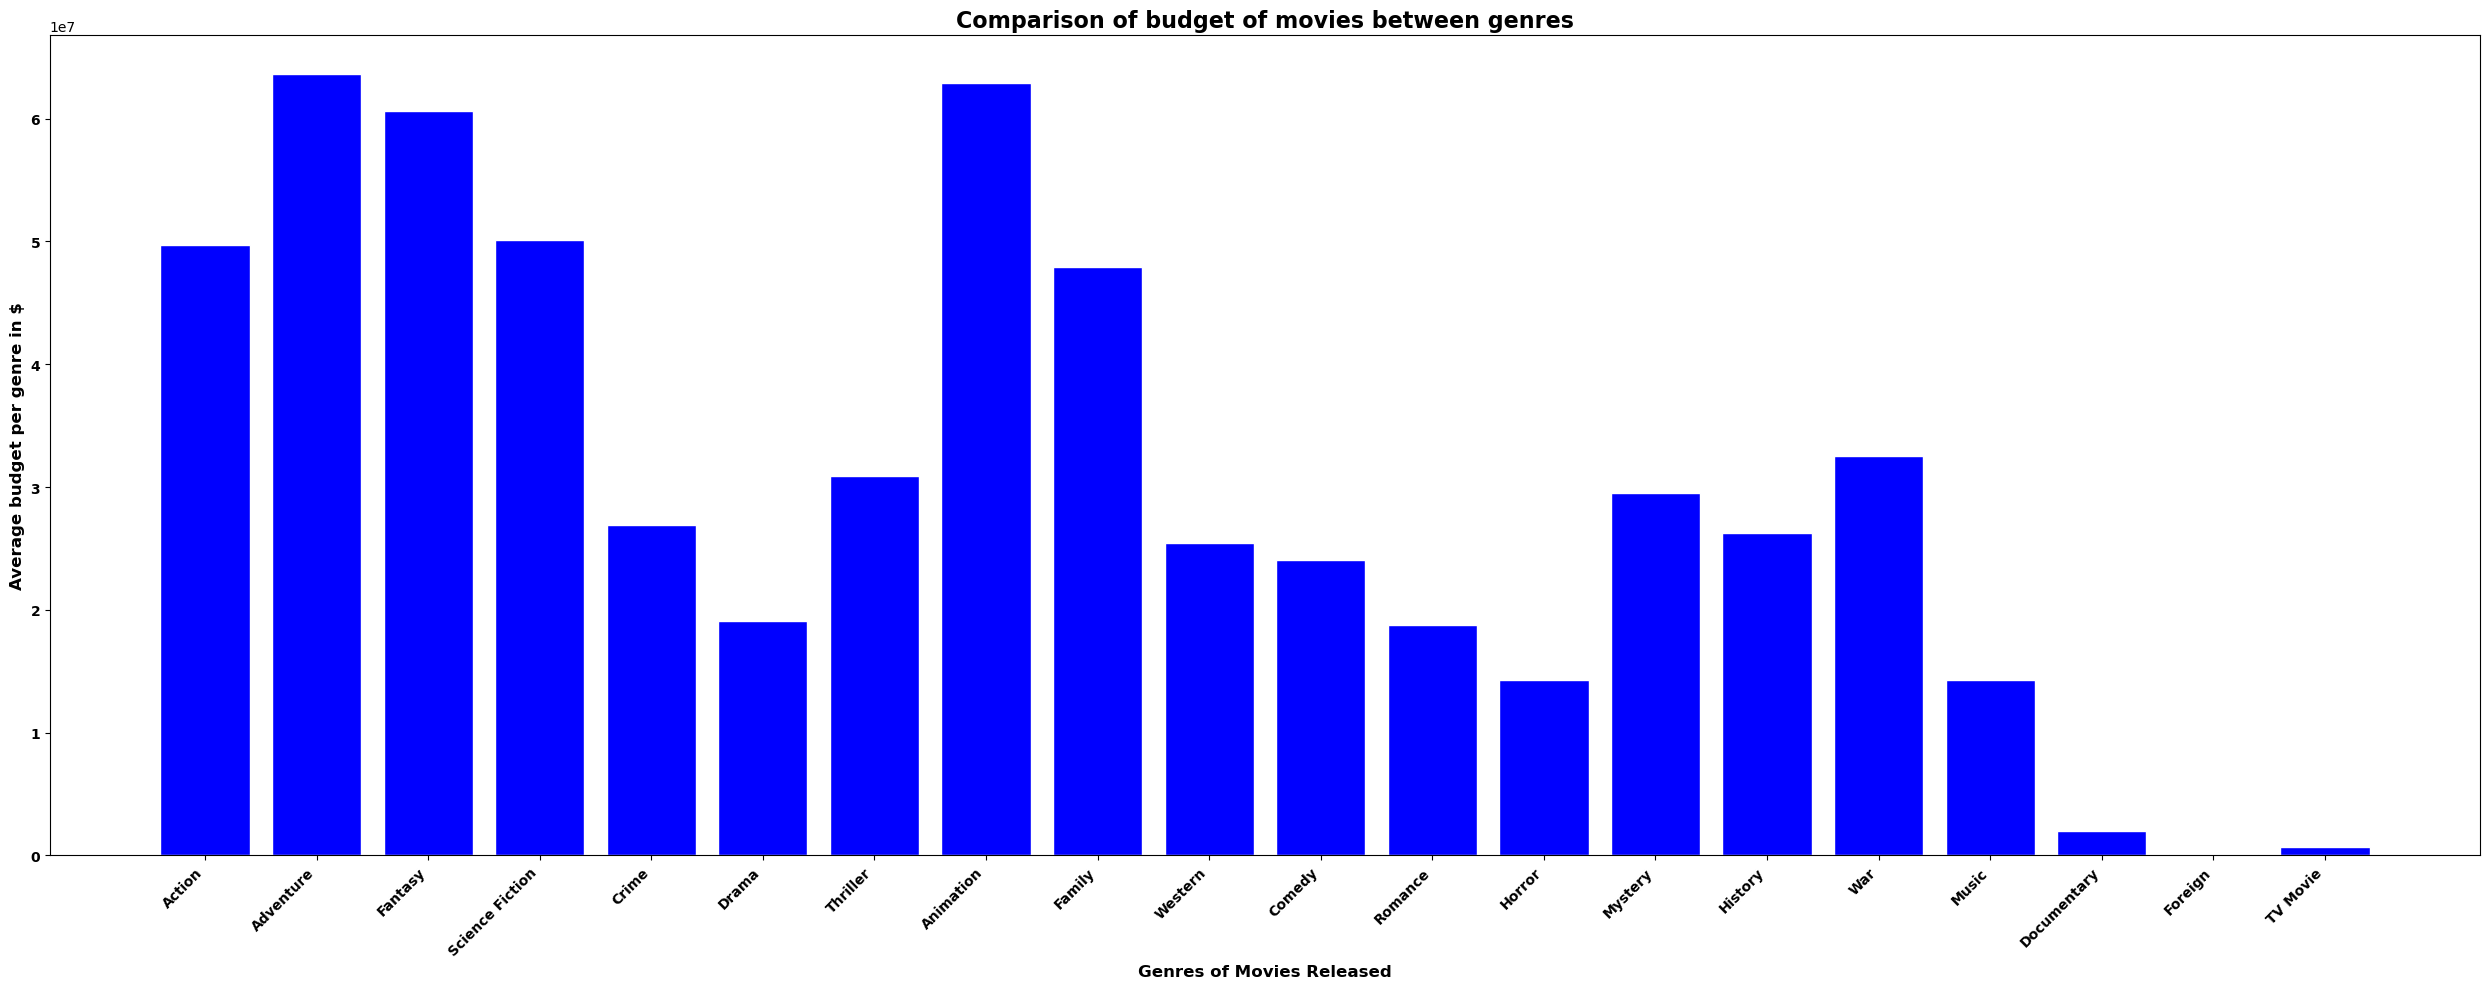

In [42]:
fig, ax = plt.subplots(figsize=(25,10))
y3_vals = [genre_profit[genre]['budget'] for genre in genre_profit]

bars = ax.bar(
    x_vals, y3_vals,
    color="blue",        # solid high-contrast color
    edgecolor="white",    # outline for distinction
    linewidth=1
)

ax.set_xlabel("Genres of Movies Released", fontsize=12, fontweight="bold")
ax.set_ylabel('Average budget per genre in $', fontsize=12, fontweight="bold")
ax.set_title('Comparison of budget of movies between genres', fontsize=16, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig('data/genres_budget2.png')
plt.show()

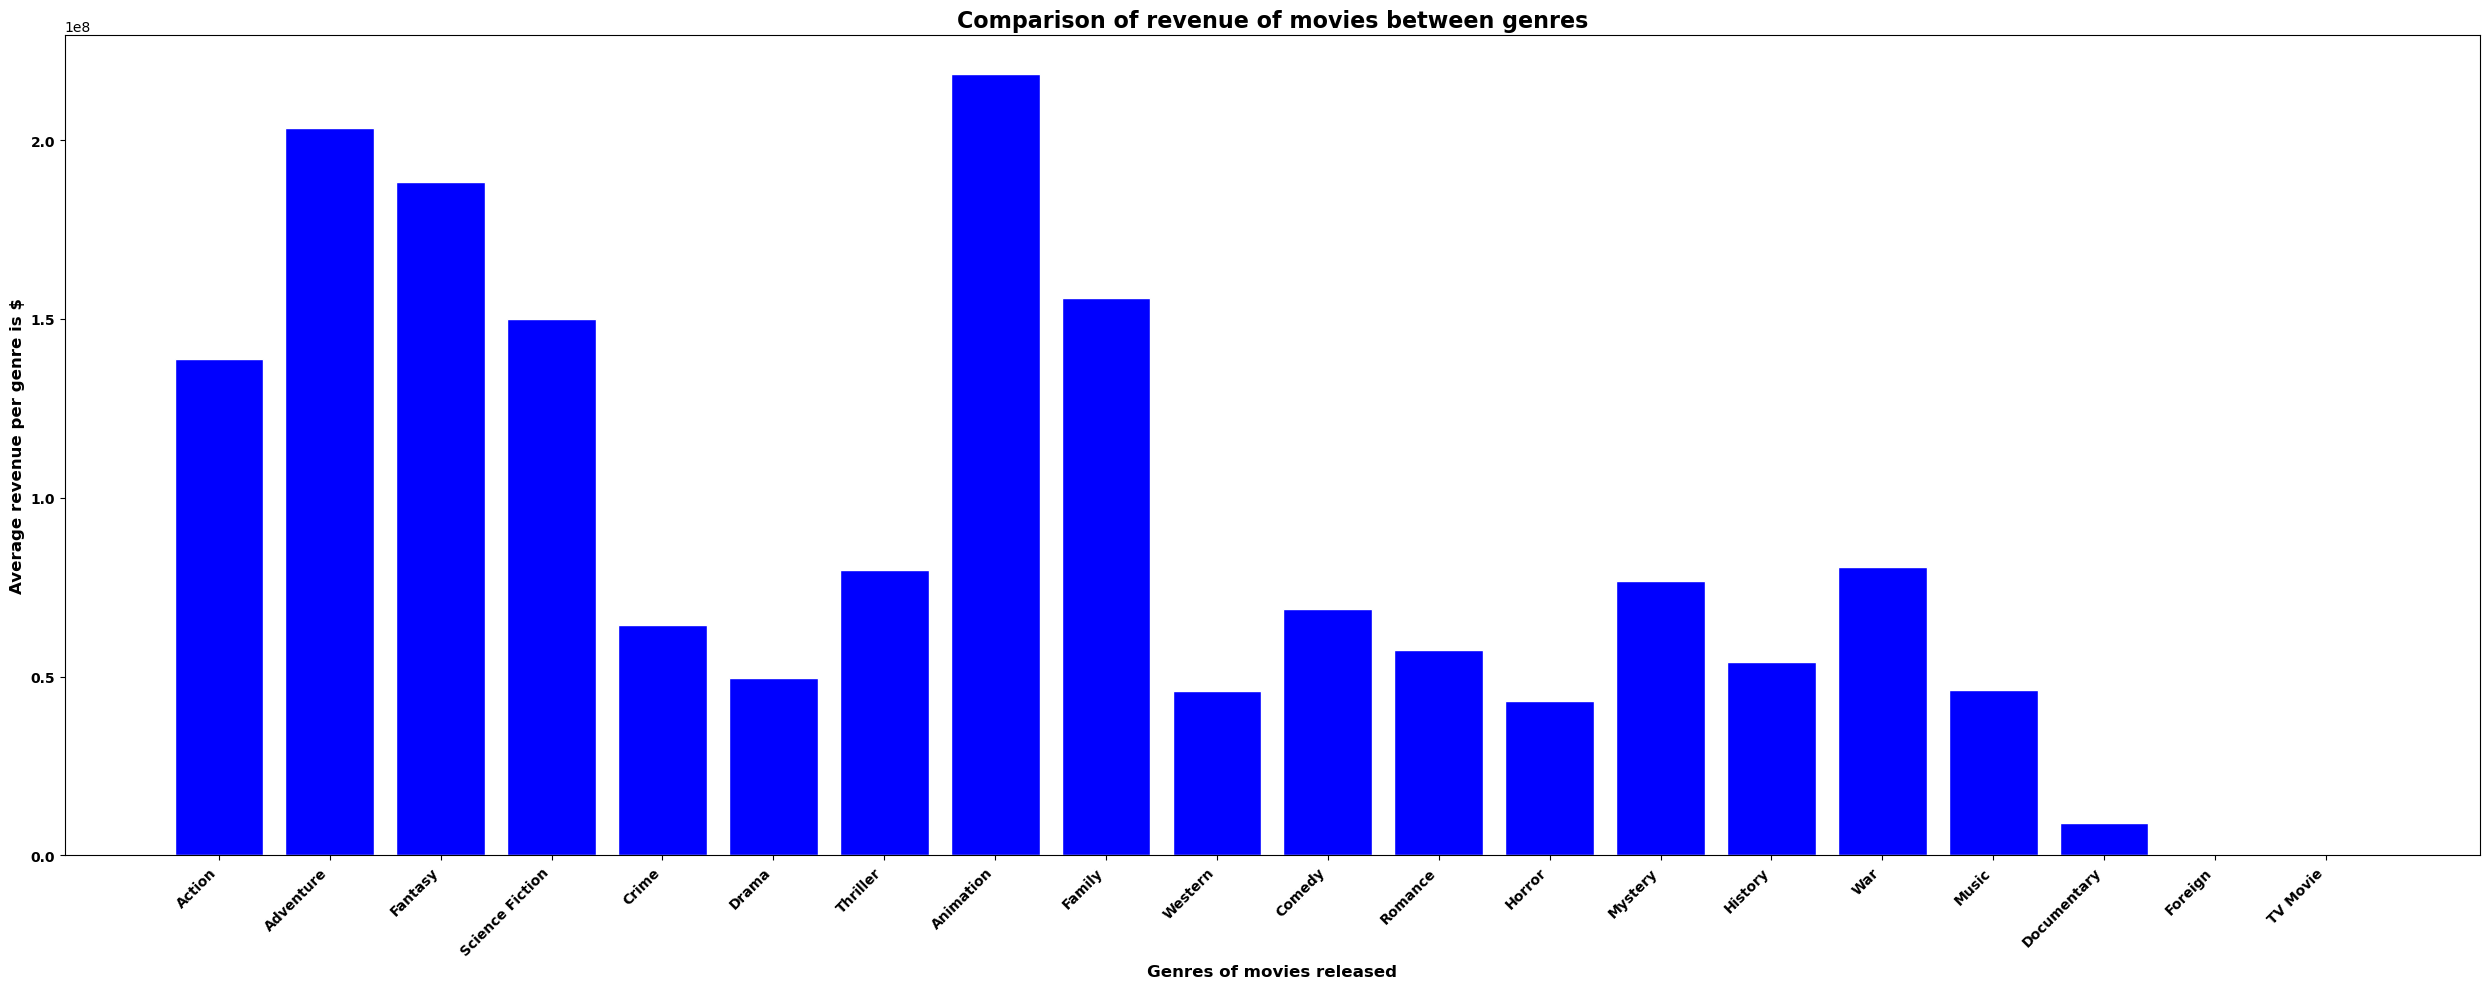

In [44]:
fig, ax = plt.subplots(figsize=(25,10))
y4_vals = [genre_profit[genre]['revenue'] for genre in genre_profit]

bars = ax.bar(
    x_vals, y4_vals,
    color="blue",        # solid high-contrast color
    edgecolor="white",    # outline for distinction
    linewidth=1
)

ax.set_xlabel('Genres of movies released', fontsize=12, fontweight="bold")
ax.set_ylabel('Average revenue per genre is $', fontsize=12, fontweight="bold")
ax.set_title('Comparison of revenue of movies between genres', fontsize=16, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig('data/genres_revenue2.png')
plt.show()

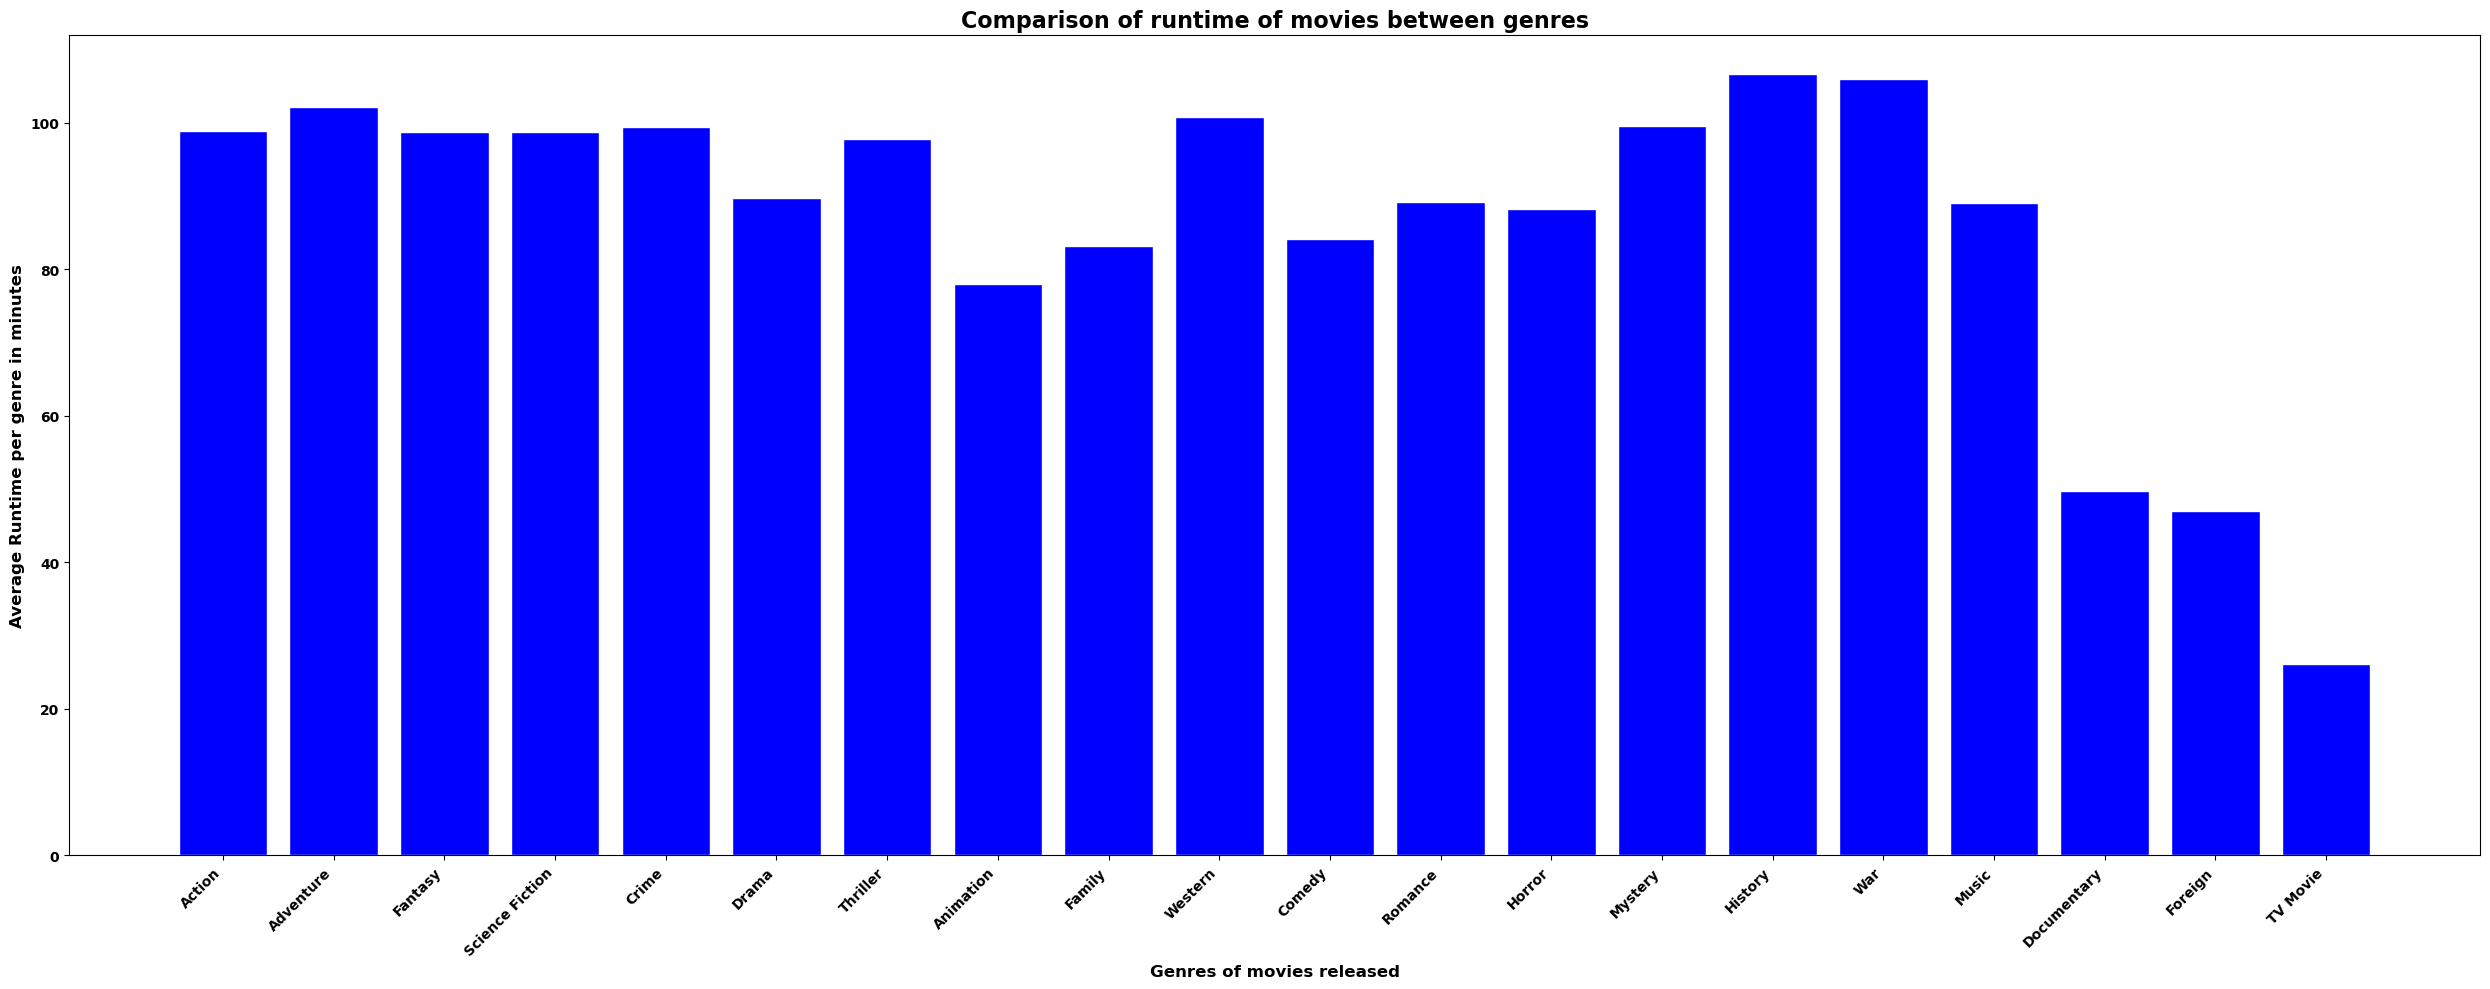

In [45]:
fig, ax = plt.subplots(figsize=(25,10))
y5_vals = [genre_profit[genre]['runtime'] for genre in genre_profit]

bars = ax.bar(
    x_vals, y5_vals,
    color="blue",        # solid high-contrast color
    edgecolor="white",    # outline for distinction
    linewidth=1
)

ax.set_xlabel('Genres of movies released', fontsize=12, fontweight="bold")
ax.set_ylabel('Average Runtime per genre in minutes', fontsize=12, fontweight="bold")
ax.set_title('Comparison of runtime of movies between genres', fontsize=16, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig('data/genres_runtime2.png')
plt.show()

In [ ]:
def get_top_n_heapq(data_dict, n, val):
    """Get top n entries by count using heapq"""
    top_n = heapq.nlargest(n, data_dict.items(), key=lambda x: x[1][val])
    return dict(top_n)

In [49]:
data = genre_profit

In [ ]:
print("Top 5 by Profit:")
top_5_profit = get_top_n_heapq(data, 5, 'profit')
for name, stats in top_5_profit.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']}
    """)

print("\nTop 5 by Count:")
top_5_count = get_top_n_heapq(data, 5, 'count')
for name, stats in top_5_count.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']}
    """)

print("\nTop 5 by Revenue:")
top_5_revenue = get_top_n_heapq(data, 5, 'revenue')
for name, stats in top_5_revenue.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']}
    """)

print("\nTop 5 by Budget:")
top_5_budget = get_top_n_heapq(data, 5, 'budget')
for name, stats in top_5_budget.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']}
    """)

print("\nTop 5 by Runtime:")
top_5_runtime = get_top_n_heapq(data, 5, 'runtime')
for name, stats in top_5_runtime.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']}
    """)

In [ ]:
print("Top 10 by Profit:")
top_10_profit = get_top_n_heapq(data, 10, 'profit')
for name, stats in top_10_profit.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']},
    """)

print("\nTop 10 by Count:")
top_10_count = get_top_n_heapq(data, 10, 'count')
for name, stats in top_10_count.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']},
    """)

print("\nTop 10 by Revenue:")
top_10_revenue = get_top_n_heapq(data, 10, 'revenue')
for name, stats in top_10_revenue.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']},
    """)

print("\nTop 10 by Budget:")
top_10_budget = get_top_n_heapq(data, 10, 'budget')
for name, stats in top_10_budget.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']}
    """)

print("\nTop 10 by Runtime:")
top_10_runtime = get_top_n_heapq(data, 10, 'runtime')
for name, stats in top_10_runtime.items():
    print(f"""{name}:
          Profit = ${stats['profit']:,},
          Count = {stats['count']},
          Revenue = {stats['revenue']},
          Budget = {stats['budget']},
          Runtime = {stats['runtime']}
    """)

In [52]:
top_genres = {
    '5': {
        'profit': top_5_profit,
        'count': top_5_count,
        'budget': top_5_budget,
        'revenue': top_5_revenue,
        'runtime': top_5_runtime
    },
    '10': {
        'profit': top_10_profit,
        'count': top_10_count,
        'revenue': top_10_revenue,
        'budget': top_10_budget,
        'runtime': top_10_runtime
    }
}

In [96]:
with open('data/top_genres.json', 'w') as f:
    json.dump(top_genres, f)

# Stacked Area Chart

In [7]:
with open('data/top_genres.json', 'r') as f:
    top_genres = json.load(f)

In [8]:
top5_genres = top_genres['5']

In [ ]:
total_yearwise = dict()
data = movies_df[['id', 'release_date', 'profit', 'budget', 'revenue']]
for measure in top5_genres.keys():
    genres = list(top5_genres[measure].keys())
    # for each genre, get its count of movies per year
    yearwise = {g:dict() for g in genres}

    for i in range(len(data)):
        movie_row = data.iloc[i]
        date = movie_row['release_date']
        movie_id = movie_row['id']
        # get the genre_id from genre_map with the given movie_id
        genre_ids = genres_map_df[genres_map_df['movie_id'] == movie_id]['genre_id']
        # get the genre_names from genres with given genre_id
        genre_names = [list(genres_df[genres_df['id'] == g]['name'])[0] for g in genre_ids]
        year = date.split('-')[0]

        for genre_name in genre_names:
            if genre_name in genres:
                if year not in yearwise[genre_name]:
                    yearwise[genre_name][year] = 1
                else:
                    yearwise[genre_name][year] += 1
    else:
        total_yearwise[measure] = yearwise

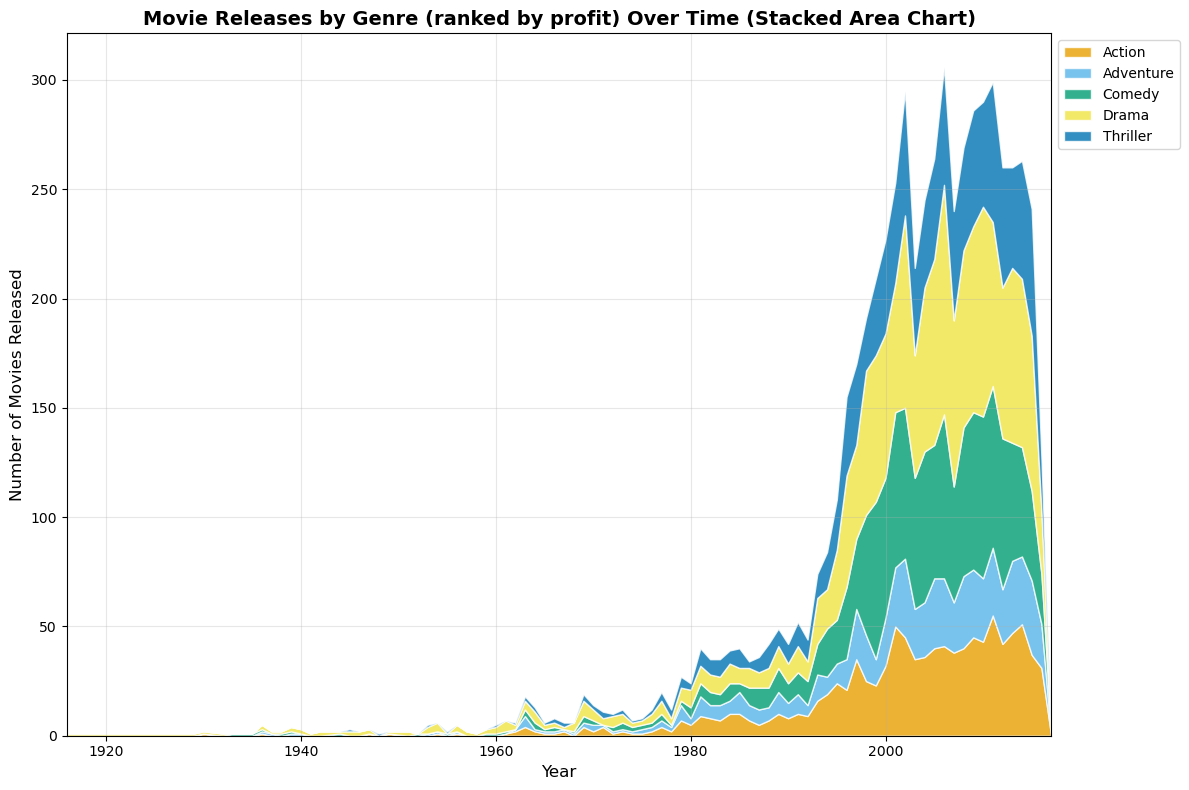

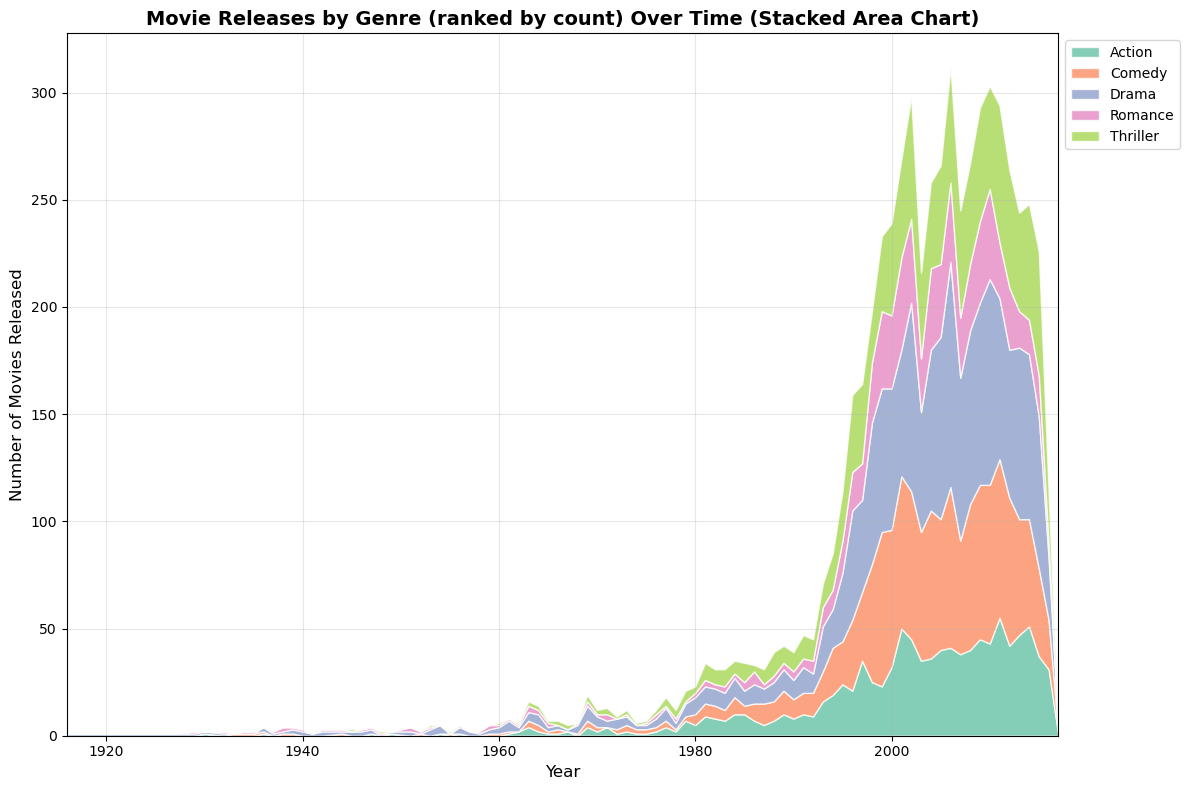

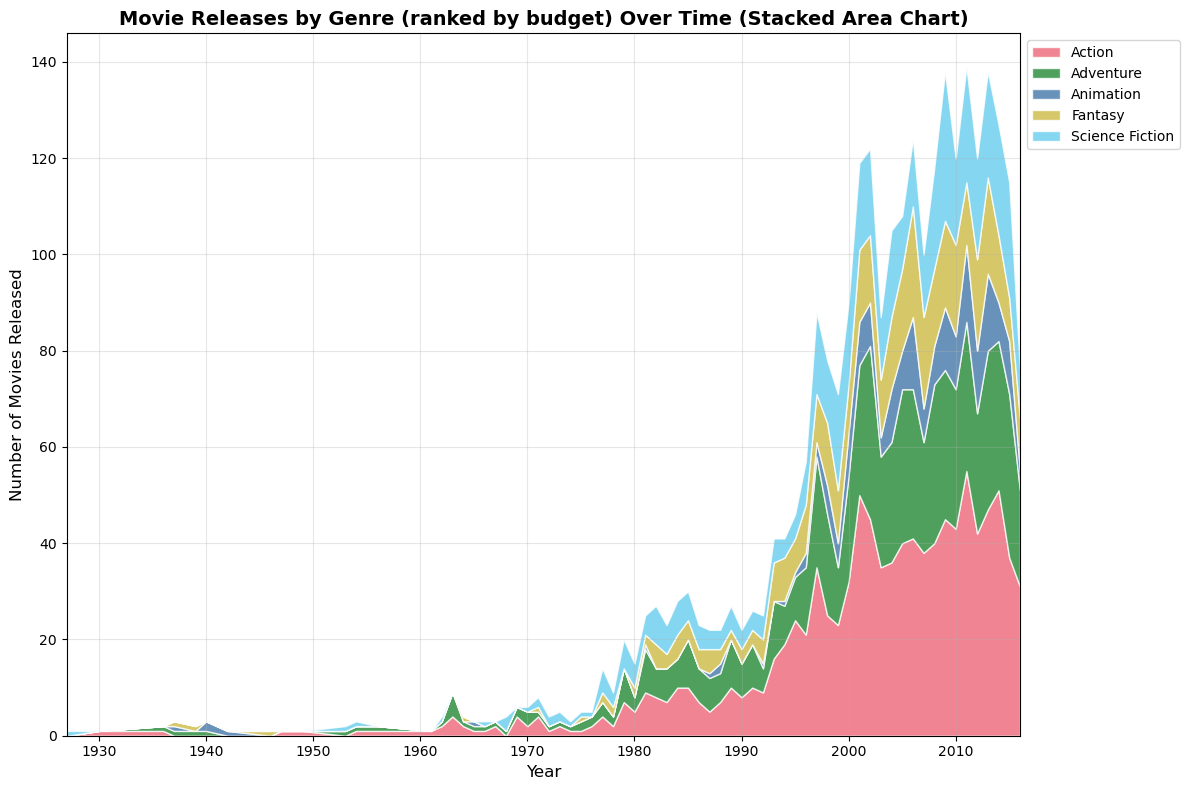

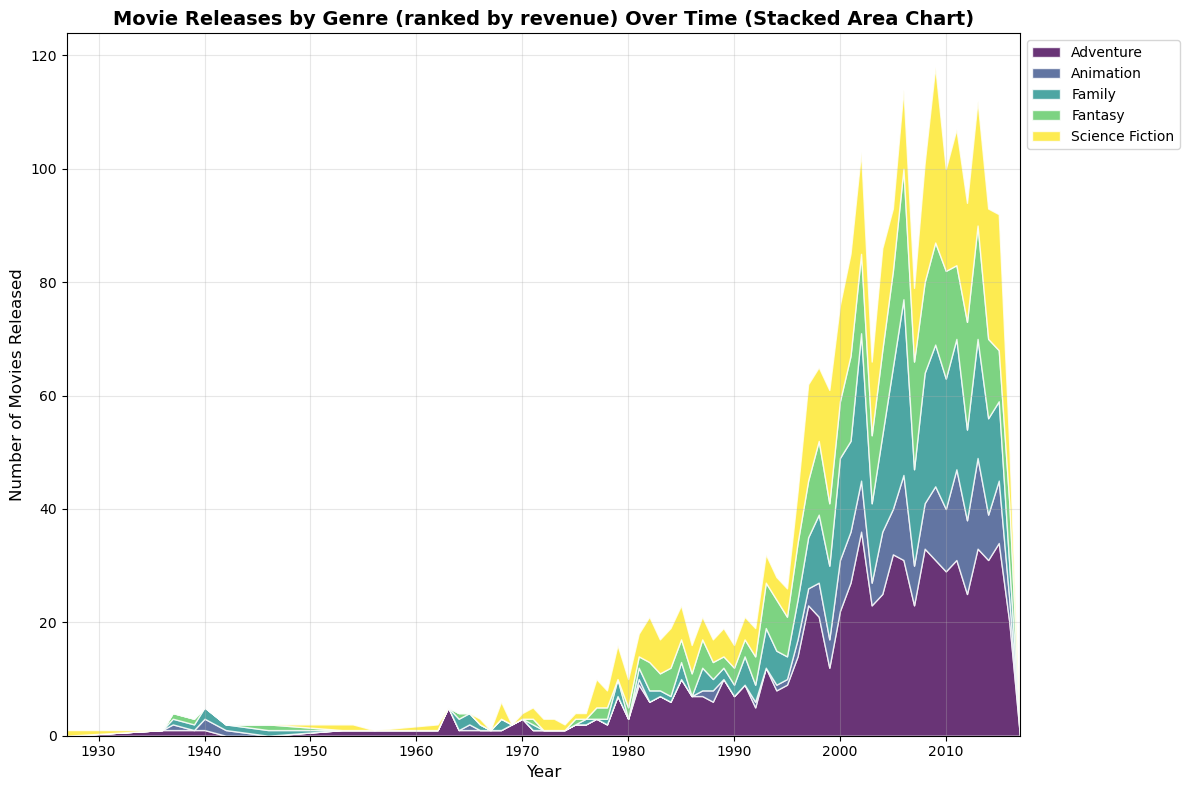

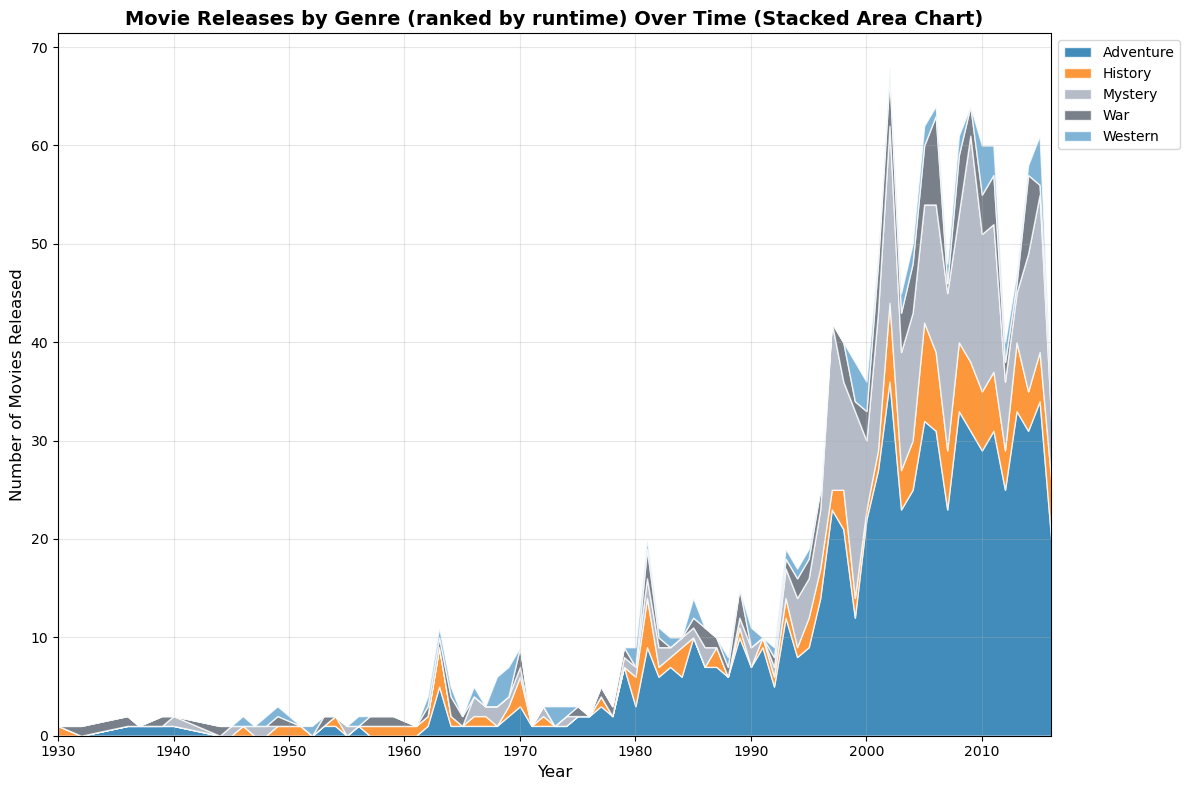

In [38]:
colorblind_friendly_colors = [
    [
        "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2"
    ],
    [
        "#66C2A5", "#FC8D62", "#8DA0CB", "#E78AC3", "#A6D854"
    ],
    [
        "#EE6677", "#228833", "#4477AA", "#CCBB44", "#66CCEE"
    ],
    [
        "#440154", "#3B528B", "#21908C", "#5DC863", "#FDE725"
    ],
    [
        "#1170AA", "#FC7D0B", "#A3ACB9", "#57606C", "#5FA2CE"
    ]
]

for j in range(len(list(total_yearwise.keys()))):
    measure = list(total_yearwise.keys())[j]
    colors = colorblind_friendly_colors[j]
    data = total_yearwise[measure]
    df_data = []
    for genre, years_data in data.items():
        for year, count in years_data.items():
            df_data.append({'Genre': genre, 'Year': int(year), 'Count': count})
    df = pd.DataFrame(df_data)

    # We pivot the dataframe per year per genre as counts
    pivot_df = df.pivot(index='Year', columns='Genre', values='Count').fillna(0)
    pivot_df = pivot_df.sort_index()
    years = pivot_df.index
    genres = pivot_df.columns

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.stackplot(years,
                *pivot_df.T.values,
                labels=genres,
                colors=colors,
                edgecolor='white',
                alpha=0.8)
    ax.set_xlabel('Year', fontsize=12)
    ax.set_ylabel('Number of Movies Released', fontsize=12)
    ax.set_title(f'Movie Releases by Genre (ranked by {measure}) Over Time (Stacked Area Chart)', fontsize=14, fontweight='bold')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.grid(True, alpha=0.3)
    ax.set_xlim(min(years), max(years))
    plt.tight_layout()
    plt.savefig(f'data/stacked_area_chart_{measure}_2.png')
    plt.show()

# Bar chart of Average Revenue and Budget

In [53]:
top10_genres = top_genres['10']

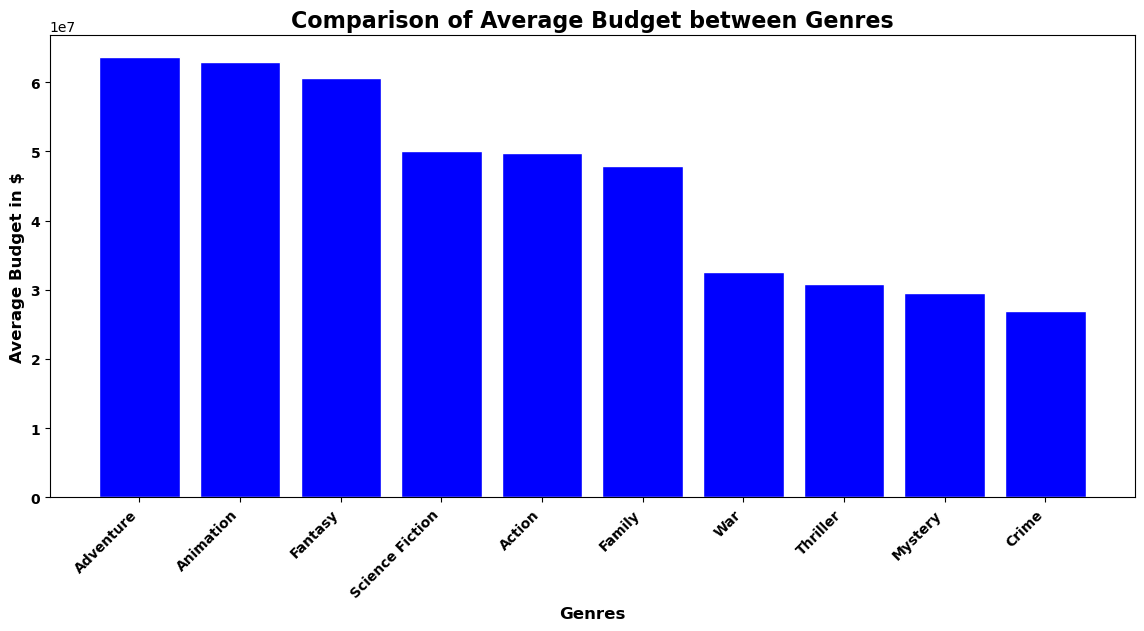

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))
x_vals = top10_genres['budget'].keys()
y_vals = [top10_genres['budget'][genre]['budget'] for genre in top10_genres['budget']]

bars = ax.bar(
    x_vals, y_vals,
    color="blue",        # solid high-contrast color
    edgecolor="white",    # outline for distinction
    linewidth=1
)

ax.set_xlabel('Genres', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Budget in $', fontsize=12, fontweight='bold')
ax.set_title('Comparison of Average Budget between Genres', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha="right", fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.savefig('data/bar_budget_genre2.png')
plt.show()

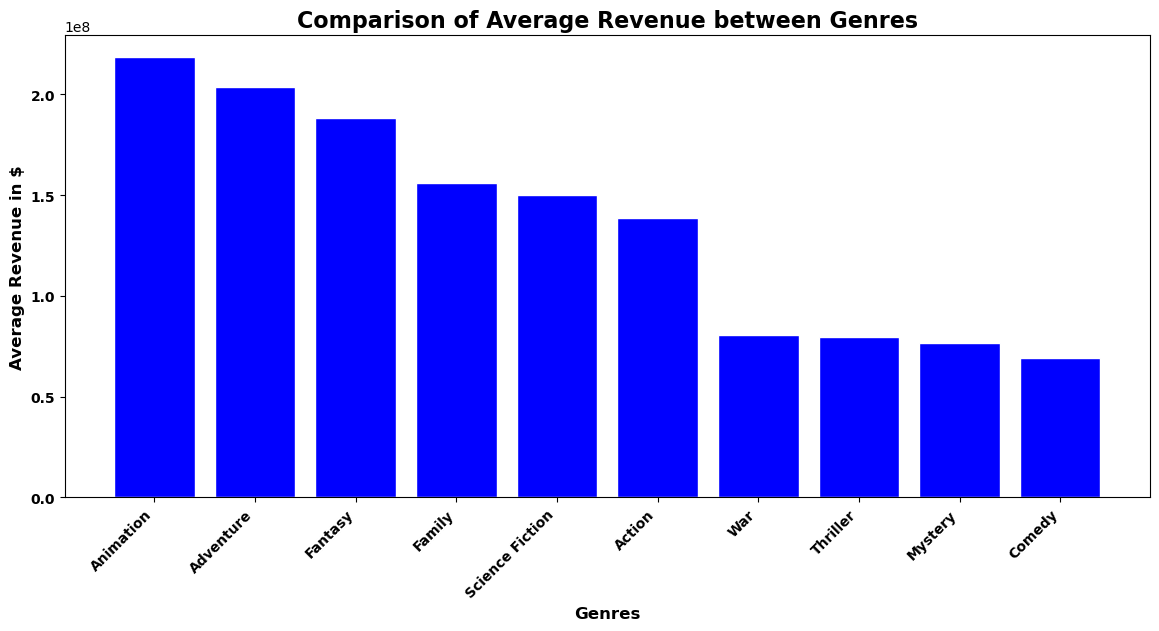

In [56]:
fig, ax = plt.subplots(figsize=(14,6))
x_vals = top10_genres['revenue'].keys()
y_vals = [top10_genres['revenue'][genre]['revenue'] for genre in top10_genres['revenue']]

bars = ax.bar(
    x_vals, y_vals,
    color="blue",        # solid high-contrast color
    edgecolor="white",    # outline for distinction
    linewidth=1
)

ax.set_xlabel('Genres', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Revenue in $', fontsize=12, fontweight='bold')
ax.set_title('Comparison of Average Revenue between Genres', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha="right", fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.savefig('data/bar_revenue_genre2.png')
plt.show()

# Violin Plot

In [ ]:
director_credits = crew_df[crew_df['job'] == 'Director'] # all directors

In [39]:
credits = list(director_credits['credit_id'])
directors = list(director_credits['name'])

In [ ]:
mov_d = {d : {
    'count': 0, 'credit': 0, 'vote_average': [], 'profit': [], 'popularity': []
    } for d in directors}
for d_id, director in zip(credits, directors):
    # using credit_id, get movie_id from crew_map
    l = list(crew_map_df[crew_map_df['credit_id'] == d_id]['movie_id'])
    # using movie_ids get vote_average, popularity, profit from movies
    va = [list(movies_df[movies_df['id'] == movie_id]['vote_average']) for movie_id in l][0]
    profit = [list(movies_df[movies_df['id'] == movie_id]['profit']) for movie_id in l][0]
    popularity = [list(movies_df[movies_df['id'] == movie_id]['popularity']) for movie_id in l][0]
    mov_d[director]['popularity'] += popularity
    mov_d[director]['count'] += len(l)
    mov_d[director]['credit'] = d_id
    mov_d[director]['vote_average'] += va
    mov_d[director]['profit'] += profit

In [ ]:
for director in mov_d:
    mov_d[director]['vote_average'] = float(np.average(mov_d[director]['vote_average']))
    mov_d[director]['profit_average'] = float(np.average(mov_d[director]['vote_average']))

In [49]:
top5_d = heapq.nlargest(5, mov_d.items(), key=lambda x: x[1]['count'])

In [18]:
x_vals = [i[0] for i in top5_d]
y_vals = [i[1]['vote_average'] for i in top5_d]

In [ ]:
categories = x_vals
data_lists = y_vals

In [ ]:
def create_violin_plot_seaborn(categories, data_lists):
    plot_data = []
    for category, values in zip(categories, data_lists):
        for value in values:
            plot_data.append({'Category': category, 'Value': value})
    
    df = pd.DataFrame(plot_data)
    
    plt.figure(figsize=(12, 8))
    sns.violinplot(data=df, x='Category', y='Value', palette='Set2')
    plt.title('Violin Plot of 5 Categories', fontsize=16, fontweight='bold')
    plt.xlabel('Categories', fontsize=12)
    plt.ylabel('Values', fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('data/violin_simple.png')
    plt.show()

def create_advanced_violin_plot(categories, data_lists):
    plot_data = []
    for category, values in zip(categories, data_lists):
        for value in values:
            plot_data.append({'Category': category, 'Value': value})
    
    df = pd.DataFrame(plot_data)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    
    sns.violinplot(data=df, x='Category', y='Value', ax=ax1, palette='viridis', inner='box')
    ax1.set_title('Violin Plot with Box Plot Inside', fontsize=14, fontweight='bold')
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
    ax1.grid(axis='y', alpha=0.3)
    
    sns.violinplot(data=df, x='Category', y='Value', ax=ax2, palette='plasma', alpha=0.6)
    sns.swarmplot(data=df, x='Category', y='Value', ax=ax2, color='black', alpha=0.8, size=3)
    ax2.set_title('Violin Plot with Swarm Plot Overlay', fontsize=14, fontweight='bold')
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
    ax2.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('data/violin_advanced.png')
    plt.show()

def print_statistics(categories, data_lists):
    print("Basic Statistics for Each Category:")
    print("-" * 60)
    for category, values in zip(categories, data_lists):
        values_array = np.array(values)
        print(f"{category}:")
        print(f"  Mean: {np.mean(values_array):.3f}")
        print(f"  Median: {np.median(values_array):.3f}")
        print(f"  Std Dev: {np.std(values_array):.3f}")
        print(f"  Min: {np.min(values_array):.3f}")
        print(f"  Max: {np.max(values_array):.3f}")
        print(f"  Count: {len(values_array)}")
        print()

In [ ]:
print_statistics(categories, data_lists)

print("Creating Seaborn violin plot...")
create_violin_plot_seaborn(categories, data_lists)
create_advanced_violin_plot(categories, data_lists)

# Hypothesis Testing

In [ ]:
measure = 'runtime'
x = list(set(list(movies_df['release_date'])))
# given release_date, get total runtime values from movies
y = [sum(movies_df[movies_df['release_date'] == i][measure]) for i in x]

ordered_pop = {i:j for i, j in zip(x, y)}
s = sorted(x)
order_pop = {i: ordered_pop[i] for i in s}
years = sorted([eval(i.split('-')[0]) for i in order_pop])  # converting dates to years
decades = range(1910, 2020, 10)  # getting the decades

# getting representative for each decade
gaps = [str(int(np.median([year for year in years if decade<=year<(decade+10)]))) for decade in decades]
y_vals = order_pop.values()
gap_y = dict()
for i in order_pop:
    # get the prefix for each representative e.g 197 for 1970s
    m_year = [j for j in gaps if j.startswith((i.split('-')[0][:-1]))][0]
    if m_year not in gap_y:
        gap_y[m_year] = [order_pop[i]]
    else:
        gap_y[m_year].append(order_pop[i])

gap_y_max = {i: max(gap_y[i]) for i in gap_y}
gap_y_min = {i: min(gap_y[i]) for i in gap_y}
gap_y_avg = {i: float(np.average(gap_y[i])) for i in gap_y}

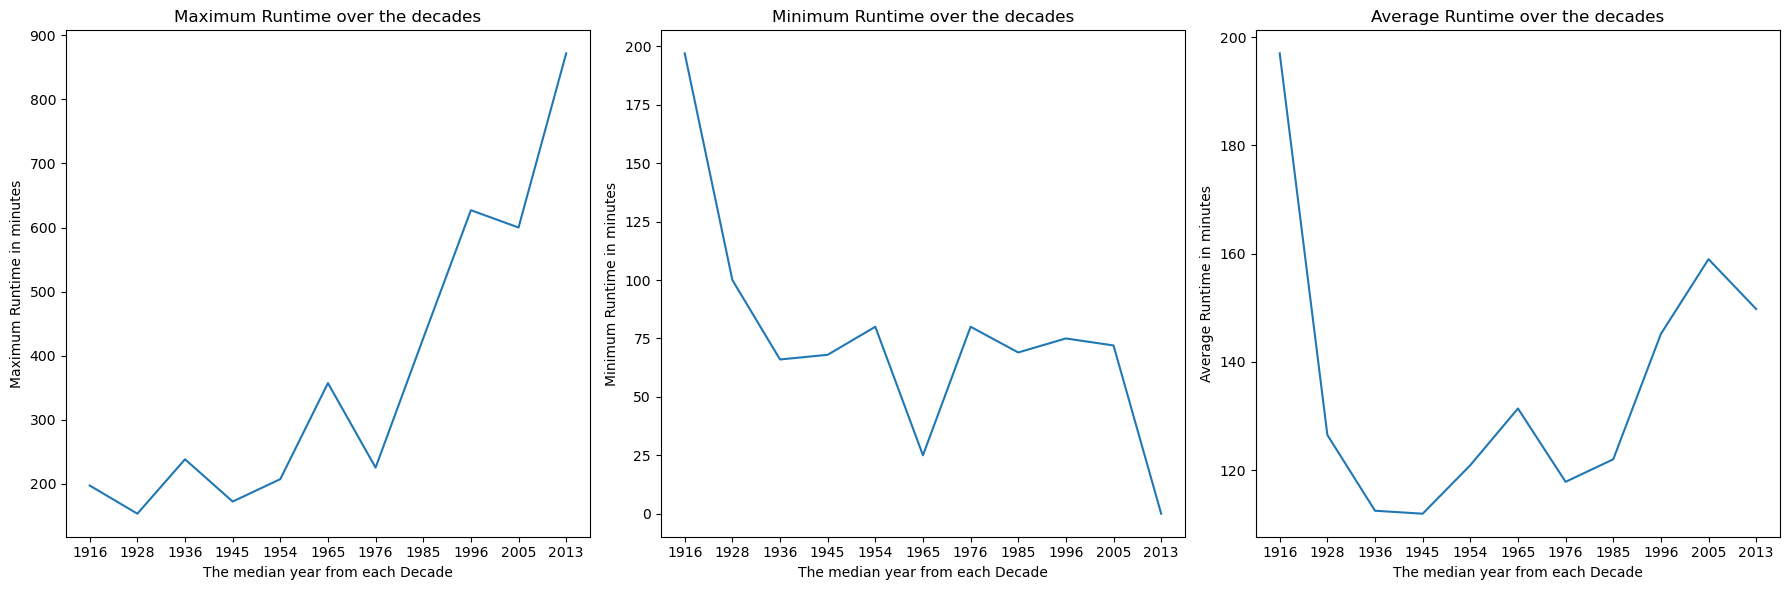

In [ ]:
x_vals = gap_y_max.keys()
y_vals_max = gap_y_max.values()
y_vals_min = gap_y_min.values()
y_vals_avg = gap_y_avg.values()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Maximum subplot
sns.lineplot(x=x_vals, y=y_vals_max, ax=axes[0])
axes[0].set_xlabel('The median year from each Decade')
axes[0].set_ylabel(f'Maximum {measure.capitalize()} in minutes')
axes[0].set_title(f'Maximum {measure.capitalize()} over the decades')

# Minimum subplot
sns.lineplot(x=x_vals, y=y_vals_min, ax=axes[1])
axes[1].set_xlabel('The median year from each Decade')
axes[1].set_ylabel(f'Minimum {measure.capitalize()} in minutes')
axes[1].set_title(f'Minimum {measure.capitalize()} over the decades')

# Average subplot
sns.lineplot(x=x_vals, y=y_vals_avg, ax=axes[2])
axes[2].set_xlabel('The median year from each Decade')
axes[2].set_ylabel(f'Average {measure.capitalize()} in minutes')
axes[2].set_title(f'Average {measure.capitalize()} over the decades')

plt.tight_layout()
plt.savefig(f'data/{measure}_subplots_year.png')
plt.show()